In [6]:

import pandas as pd
from wfield import *
import pickle
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))
# sys.path.append('./ICA')
from NatMovie_utils import *
from os.path import join as pjoin
from glob import glob
import seaborn as sns

from jadeR import jadeR
from jadeR_cupy import jadeR_cupy

os.environ['CUDA_VISIBLE_DEVICES'] = '3'
import cupy as cp


## PCA and concatenate

In [14]:

path_list = glob(pjoin('/home/lzx/data/WF_VC_liuzhaoxi/','*/natural-movie*/process/*-wfield'))
path_list

['/home/lzx/data/WF_VC_liuzhaoxi/24.01.03_C83/natural-movie/process/20240103-131221-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.01.22_C83/natural-movie/process/20240122-194422-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.04.03_C92/natural-movie/process/20240403-161209-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.04.03_C92/natural-movie/process/20240403-172109-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.04.03_C92/natural-movie/process/20240403-192107-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.05.07_H78/natural-movie/process/20240507-113351-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.05.07_H78/natural-movie/process/20240507-121035-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.05.07_H78-DOM/natural-movie/process/20240507-182626-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.05.20_H78/natural-movie/process/20240520-180021-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.05.20_H78/natural-movie/process/20240520-185133-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.03.27_C92/natural-movie/proces

In [20]:
path_list.index('/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie/process/20241219-183603-wfield')

0

In [16]:
path_list=path_list[16:]
path_list

['/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie/process/20241219-183603-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie/process/20241219-192319-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie/process/20241219-182821-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie-invert/process/20241219-201009-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie-invert/process/20241219-231104-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie-reverse/process/20241219-210558-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/25.01.10_P41/natural-movie/process/20250110-013702-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/25.01.10_P41/natural-movie-invert/process/20250110-020719-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/25.01.10_P41/natural-movie-reverse/process/20250110-024923-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/25.01.10_U26/natural-movie/process/20250110-174419-wfield',
 '/home/lzx/data/WF_VC_liuzhaoxi/

In [220]:
path_list[28]

'/home/lzx/data/WF_VC_liuzhaoxi/25.01.12_U27/natural-movie-reverse/process/20250112-031000-wfield'

In [7]:
warp_height, warp_width = (540, 640)
Xsum=np.empty((0,warp_width*warp_height))
gpath=[]
VTsum=[]
print('Xsum dim:', Xsum.shape)

for path_wfield in path_list: 
    print('\n\n\n'+path_wfield)
    experiment = os.path.basename(path_wfield)[:15]
    mouse = os.path.normpath(path_wfield).split(os.sep)[5].split('_')[1]
    print(experiment, mouse)
    trialfile = pd.read_csv(pjoin(path_wfield, 'trials.csv'), header=None).values.astype(int)
    if trialfile.shape[0] < 70:
        print("This experiment is not complete, skip.")
        continue
    path_out = pjoin(path_wfield, '..', experiment + '-natural-movie--')
    os.makedirs(path_out, exist_ok=True)
    rawPath = pjoin(path_wfield, '../../raw')
    movie_folder = pjoin(rawPath, 'natural_movies')
    movie_list = pd.read_csv(pjoin(movie_folder, 'movie_list.txt'), header=None).values
    n_movie = movie_list.size
    movie_name_list = []
    for imovie in range(n_movie):
        movie_name_list.append(str(movie_list[imovie])[2:-6])
    
    n_frame = 150  # 帧
    pre_length = 20
    after_length = 30
    trial_length = n_frame+pre_length+after_length
    whole_length = trialfile[-1, 2] + 50
    frames_average = np.load(pjoin(path_wfield, 'frames_average.npy')).astype('float32')
    
        
    U = cp.load(pjoin(path_wfield, 'U.npy')).astype('float32')
    SVT = cp.load(pjoin(path_wfield, 'SVT.npy')).astype('float32')
    SVT_470 = SVT[:,::2]
    SVT_405 = SVT[:,1::2]
    SVTcorr = SVT_470-SVT_405
    # SVTcorr = cp.load(pjoin(path_wfield, 'SVTcorr.npy')).astype('float32')
    frames_average = np.load(pjoin(path_wfield, 'frames_average.npy'))
    frames_ave = frames_average[0]
    tif_height, tif_width = frames_average.shape[1:]
    #%%

    # SVTcorr_sort维度：[nSVD, trial_length, n_movie, n_rep]
    SVTcorr_sort = Gsorting_NatMov(SVTcorr, trialfile[:, 1], n_movie, n_frame, pre_length, after_length).astype('float32')
    n_rep = SVTcorr_sort.shape[-1]


    lmarks = load_allen_landmarks(pjoin(path_wfield, '../../../dorsal_cortex_landmarks.json'))
    ccf_regions_reference, proj, brain_outline = allen_load_reference('dorsal_cortex')
    # this loads the untransformed atlas
    atlas_im, areanames, brain_mask = atlas_from_landmarks_file(pjoin(path_wfield, '../../../dorsal_cortex_landmarks.json'),
                                                                do_transform=True)
    # this converts the reference to image space (unwarped)
    ccf_regions_im = allen_transform_regions(lmarks['transform'], ccf_regions_reference,
                                            resolution=lmarks['resolution'],
                                            bregma_offset=lmarks['bregma_offset'])

    from skimage.transform import warp
    U_warped = cp.asarray(warp(U.get(),lmarks['transform'],
                    order = 1, mode='constant', cval = 0, clip=True, preserve_range=True, output_shape=(warp_height, warp_width)))


    path_out_ICA = pjoin(path_wfield, '..', experiment + '-natural-movie--', f'{mouse}-{experiment}-ICA-spatial-group')
    os.makedirs(path_out_ICA, exist_ok=True)


    #%%
    """
    根据 U 和 SVTcorr 计算校正后的 PCA 结果
    参数:
        U: numpy.ndarray, (P, k)
            空间基底矩阵，像素 × 成分
        SVT: numpy.ndarray, (k, T, 2)
            时间系数矩阵，k 成分 × 帧数 × 通道数
            通道 0 = 470nm, 通道 1 = 405nm
    返回:
        U_corr: numpy.ndarray, (P, r)
            校正后空间主成分载荷
        Sigma_corr: numpy.ndarray, (r,)
            奇异值（能量大小）
        Vt_corr: numpy.ndarray, (r, T)
            时间主成分
        PC_scores: numpy.ndarray, (P, r)
            像素方向的主成分得分
    """

    # SVTcorr_sort维度：[nSVD, trial_length, n_movie, n_rep]
    A, Sigma_sort, Vt_sort = cp.linalg.svd(SVTcorr_sort.reshape(-1,trial_length*n_movie*n_rep), full_matrices=False)



    # 计算像素主成分得分(P, r)
    PC_scores = (U_warped @ A) @ cp.diag(Sigma_sort)
    # PC_scores = (U @ A) @ cp.diag(Sigma_sort)

    np.save(pjoin(path_out_ICA,'PC_scores.npy'),PC_scores)
    np.save(pjoin(path_out_ICA,'Vt_sort.npy'),Vt_sort)
    print(f'PC_scores.shape:{PC_scores.shape:}\nVt_sort.shape:{Vt_sort.shape}')
    
    VTsum.append(Vt_sort)
    gpath.append(path_out_ICA)
    X = PC_scores.reshape(warp_width*warp_height, -1).T
    Xsum=np.concatenate((Xsum,X.get()),axis=0)
    print('Xsum dim:', Xsum.shape)
    print('VTsum length:', len(VTsum))

    del U,SVT,SVT_405,SVT_470,SVTcorr,SVTcorr_sort,A, Sigma_sort, Vt_sort,PC_scores,X
    cp._default_memory_pool.free_all_blocks()



Xsum dim: (0, 345600)



/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie/process/20241219-183603-wfield
20241219-183603 P41
This experiment is not complete, skip.



/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie/process/20241219-192319-wfield
20241219-192319 P41
PC_scores.shape:(540, 640, 200)
Vt_sort.shape:(200, 14000)
Xsum dim: (200, 345600)



/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie/process/20241219-182821-wfield
20241219-182821 P41
This experiment is not complete, skip.



/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie-invert/process/20241219-201009-wfield
20241219-201009 P41
PC_scores.shape:(540, 640, 200)
Vt_sort.shape:(200, 14000)
Xsum dim: (400, 345600)



/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie-invert/process/20241219-231104-wfield
20241219-231104 P41
This experiment is not complete, skip.



/home/lzx/data/WF_VC_liuzhaoxi/24.12.19_P41/natural-movie-reverse/process/20241219-210558-wfield
20241219-210558 P41
P

In [ ]:
%%time

VTsum=np.asarray(VTsum)
np.save(pjoin(path_out_gICA,'Xsum.npy'),Xsum)
np.save(pjoin(path_out_gICA,'VTsum.npy'),np.VTsum)
with open(pjoin(path_out_gICA,'path_list.txt'), "w", encoding="utf-8") as f:
    f.writelines("\n".join(gpath))

## groap ICA

In [3]:
path_out_gICA = r'/home/lzx/data/WF_VC_liuzhaoxi/______________natural_movie_group_ICA/'
os.makedirs(path_out_gICA, exist_ok=True)


In [154]:
warp_height, warp_width = (540, 640)


In [128]:
%%time
Xsum1 = cp.load(pjoin(path_out_gICA,'Xsum.npy'))

CPU times: user 1.66 s, sys: 1min 28s, total: 1min 30s
Wall time: 3min 5s


In [131]:
Xsum1.shape

(7400, 345600)

In [8]:
n_IC = 20


In [24]:
%%time

X = Xsum1.reshape(Xsum1.shape[0], warp_height//2, 2, warp_width//2, 2).mean(axis=(2, 4)).reshape(Xsum1.shape[0], -1)
demix_matrix = jadeR_cupy(X, m=n_IC, verbose=True)
IC = demix_matrix @ X
IC_array_bin2 = cp.asarray(IC).reshape(n_IC, warp_height//2, warp_width//2)
IC_array = cp.asnumpy(cp.kron(IC_array_bin2, cp.ones((1, 2, 2))))
mix_matrix = cp.asnumpy(cp.linalg.pinv(demix_matrix))

del demix_matrix, IC_array_bin2
cp._default_memory_pool.free_all_blocks()
    
np.save(pjoin(path_out_gICA, f'group_ICA{n_IC}.npy'), IC_array)
np.save(pjoin(path_out_gICA, f'group_ICA{n_IC}_mix.npy'), mix_matrix)

print('save ICA matrix')
print('IC_array.shape', IC_array.shape)
print('mix_matrix.shape', mix_matrix.shape)

jade -> Looking for 40 sources
jade -> Removing the mean value
jade -> Whitening the data
jade -> Estimating cumulant matrices
jade -> Contrast optimization by joint diagonalization
jade -> Sweep #  0
completed in 780 rotations
jade -> Sweep #  1
completed in 780 rotations
jade -> Sweep #  2
completed in 780 rotations
jade -> Sweep #  3
completed in 780 rotations
jade -> Sweep #  4
completed in 780 rotations
jade -> Sweep #  5
completed in 780 rotations
jade -> Sweep #  6
completed in 780 rotations
jade -> Sweep #  7
completed in 780 rotations
jade -> Sweep #  8
completed in 780 rotations
jade -> Sweep #  9
completed in 780 rotations
jade -> Sweep # 10
completed in 780 rotations
jade -> Sweep # 11
completed in 780 rotations
jade -> Sweep # 12
completed in 780 rotations
jade -> Sweep # 13
completed in 780 rotations
jade -> Sweep # 14
completed in 780 rotations
jade -> Sweep # 15
completed in 780 rotations
jade -> Sweep # 16
completed in 780 rotations
jade -> Sweep # 17
completed in 780 

In [11]:
# caculate raw data spatial variance

total_var = cp.var(X, axis=1).sum()  
cp.save(pjoin(path_out_gICA, 'total_var.npy'), total_var)

In [155]:
total_var = cp.load(pjoin(path_out_gICA, 'total_var.npy'))

In [25]:
%%time
# 计算每个 spatial IC 解释的方差比例

ic_variances = cp.zeros(n_IC)
for i in range(n_IC):
    # 计算当前 IC 的贡献（时间序列 * 空间模式）
    ic_contribution = cp.asarray(mix_matrix[:, i:i+1]) @ IC[i].reshape(1, -1)
    # 计算该 IC 的方差贡献
    ic_variances[i] = cp.var(ic_contribution, axis=1).sum() 

explained_variance_ratio = cp.asnumpy(ic_variances / total_var)

print("每个 spatial IC 解释的方差比例：")
for i, ratio in enumerate(explained_variance_ratio):
    print(f"IC {i+1}: {ratio * 100:.2f}%")

np.save(pjoin(path_out_gICA, f'ICA{n_IC}_explained_var_ratio.npy'), explained_variance_ratio)



每个 spatial IC 解释的方差比例：
IC 1: 7.55%
IC 2: 7.25%
IC 3: 6.20%
IC 4: 4.55%
IC 5: 3.91%
IC 6: 3.51%
IC 7: 3.22%
IC 8: 3.14%
IC 9: 2.92%
IC 10: 2.86%
IC 11: 2.83%
IC 12: 2.59%
IC 13: 2.32%
IC 14: 2.30%
IC 15: 2.21%
IC 16: 2.14%
IC 17: 2.08%
IC 18: 2.04%
IC 19: 1.97%
IC 20: 1.90%
IC 21: 1.87%
IC 22: 1.84%
IC 23: 1.83%
IC 24: 1.83%
IC 25: 1.80%
IC 26: 1.76%
IC 27: 1.76%
IC 28: 1.70%
IC 29: 1.64%
IC 30: 1.55%
IC 31: 1.48%
IC 32: 1.46%
IC 33: 1.12%
IC 34: 1.08%
IC 35: 1.06%
IC 36: 0.99%
IC 37: 0.93%
IC 38: 0.70%
IC 39: 0.41%
IC 40: 0.36%
CPU times: user 529 ms, sys: 14.8 ms, total: 544 ms
Wall time: 549 ms


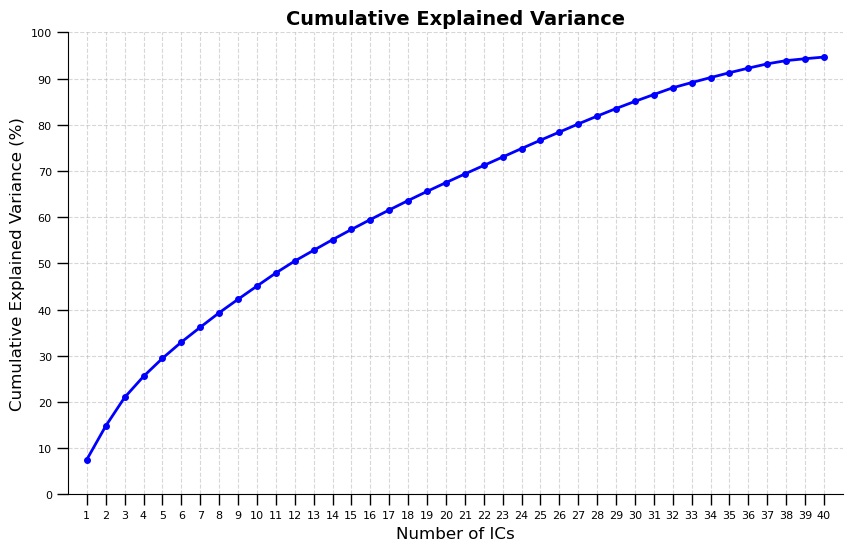

In [26]:
# 计算累计解释方差并绘图
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

fig = plt.figure(figsize=(10, 6))
plt.plot(range(1, n_IC + 1), cumulative_explained_variance * 100, 'b-o', linewidth=2, label='Cumulative Explained Variance')
# plt.axhline(y=95, color='r', linestyle='--', alpha=0.5, label='95% Threshold')
plt.xlabel('Number of ICs', fontsize=12)
plt.ylabel('Cumulative Explained Variance (%)', fontsize=12)
plt.xticks(np.arange(1, n_IC + 1, 1))   
plt.yticks(np.arange(0, 101, 10))      
plt.xlim(0, n_IC+1)
plt.ylim(0,100)
plt.title(f'Cumulative Explained Variance', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
# plt.legend()
fig.set_facecolor('white')
plt.savefig(pjoin(path_out_gICA, f'ICA{n_IC}_cumulative_variance.png'), dpi=300)
plt.show()


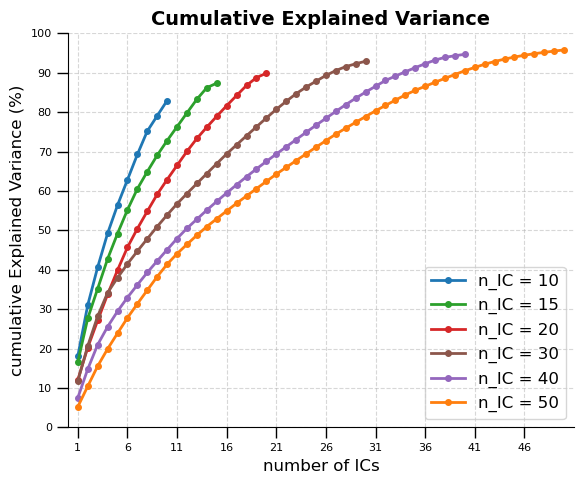

In [163]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from os.path import join as pjoin

n_IC_list = [10, 15, 20, 30, 40, 50]
colors = ['tab:blue', 'tab:green', 'tab:red', 'tab:brown', 'tab:purple', 'tab:orange']
labels = [f'n_IC = {n}' for n in n_IC_list]

fig = plt.figure(figsize=(6, 5))

for i_n_IC, color, label in zip(n_IC_list, colors, labels):
    explained_variance_ratio = np.load(pjoin(path_out_gICA, f'ICA{i_n_IC}_explained_var_ratio.npy'))

    # 计算累计解释方差
    cumulative_explained_variance = np.cumsum(explained_variance_ratio)

    # 绘图
    plt.plot(
        range(1, i_n_IC + 1),
        cumulative_explained_variance * 100,
        marker='o',
        color=color,
        linewidth=2,
        label=label
    )

# 设置图形属性
plt.xlabel('number of ICs', fontsize=12)
plt.ylabel('cumulative Explained Variance (%)', fontsize=12)
plt.xticks(np.arange(1, max(n_IC_list) + 1, 5))
plt.yticks(np.arange(0, 101, 10))
plt.xlim(0, max(n_IC_list) + 1)
plt.ylim(0, 100)
plt.title(f'Cumulative Explained Variance', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
fig.set_facecolor('white')
plt.tight_layout()

# 保存和显示图像
plt.savefig(pjoin(path_out_gICA, 'spatial-ICA_multi_cumulative_variance.png'), dpi=300)
plt.show()


In [7]:
from skimage.transform import warp

warp_height, warp_width = (540, 640)
lmarks = load_allen_landmarks('/home/lzx/data/WF_VC_liuzhaoxi/25.08.07_A11/dorsal_cortex_landmarks.json')
ccf_regions_reference, proj, brain_outline = allen_load_reference('dorsal_cortex')
ccf_regions = allen_transform_regions(None,ccf_regions_reference,
                                      resolution = lmarks['resolution'],
                                        bregma_offset = lmarks['bregma_offset'])
atlas, areanames, brain_mask = atlas_from_landmarks_file(landmarks_file=None, reference='dorsal_cortex', dims = [warp_height, warp_width], do_transform = None) 


In [9]:
IC_array = np.load(pjoin(path_out_gICA, f'group_ICA{n_IC}.npy'))
mix_matrix = np.load(pjoin(path_out_gICA, f'group_ICA{n_IC}_mix.npy'))
explained_variance_ratio = np.load(pjoin(path_out_gICA, f'ICA{n_IC}_explained_var_ratio.npy'))

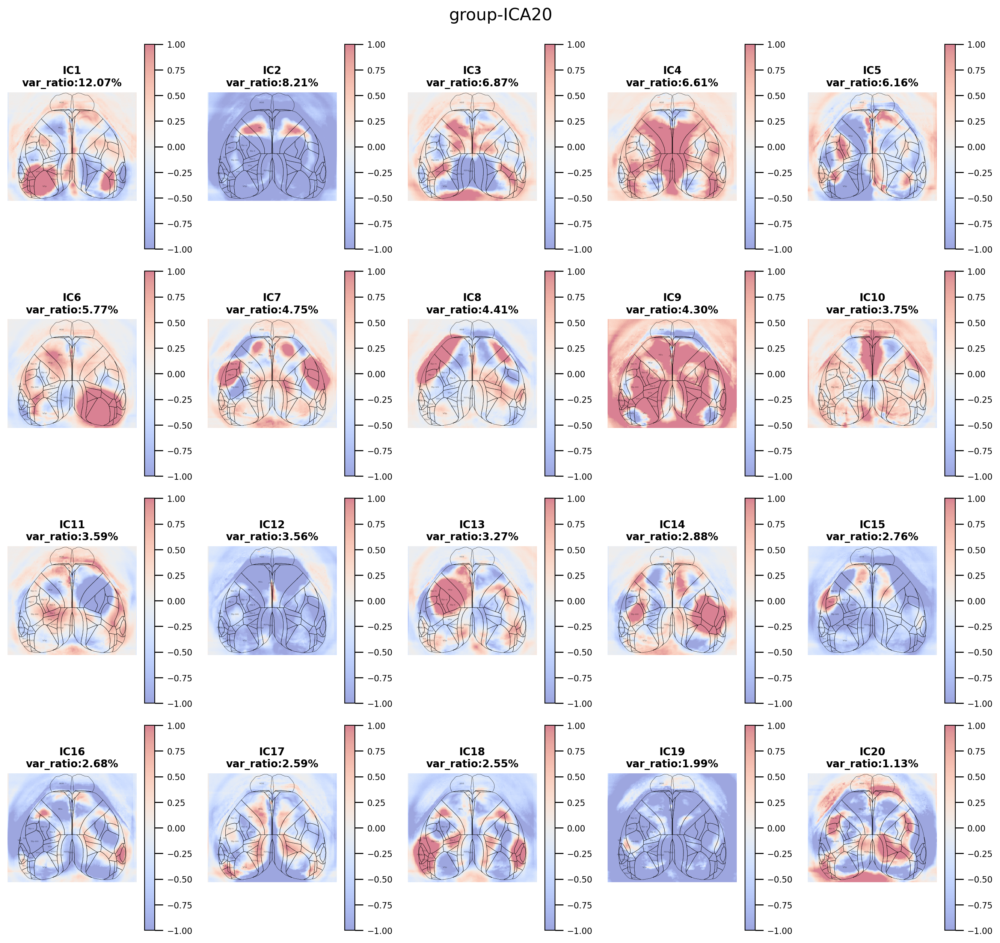

CPU times: user 12.7 s, sys: 399 ms, total: 13.1 s
Wall time: 13.2 s


In [51]:
%%time
# plot spatial IC

ncol = 5
nrow = n_IC//ncol
dpi = 200

fig, ax = plt.subplots(nrow, ncol, figsize=(warp_height / dpi * ncol, warp_width / dpi * nrow), dpi=dpi)
for irow in range(nrow):
    for icol in range(ncol):
        iIC = irow * ncol + icol
        # ax[irow, icol].imshow(frames_ave, cmap='gray')
        img = ax[irow, icol].imshow(IC_array[iIC], cmap='coolwarm', clim=[-1,1], alpha=0.5)

        ax[irow, icol].set_title(f'IC{iIC + 1}\nvar_ratio:{explained_variance_ratio[iIC]*100:.2f}%', fontsize=10)
        ax[irow, icol].axis('off')

        for idx, r in ccf_regions.iterrows():
            ax[irow, icol].plot(r['left_x'], r['left_y'], 'k', lw=0.2)
            ax[irow, icol].plot(r['right_x'], r['right_y'], 'k', lw=0.2)
            ax[irow, icol].text(r.left_center[0], r.left_center[1], r.acronym, color='k', va='center', fontsize=2,
                                alpha=0.5,
                                ha='center')
        fig.colorbar(img)
fig.set_facecolor('white')
# fig.suptitle(f'{mouse}_{experiment}\nIC{n_IC}', fontsize=16)
fig.suptitle(f'group-ICA{n_IC}', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig(pjoin(path_out_gICA, f'group_ICA{n_IC}_raw.png'), bbox_inches='tight', pad_inches=0)
plt.show()


In [221]:
# set IC threshold, adjust ± sign

def zscore(matrix, axis=(1,2)):
    mean = np.mean(matrix, axis=axis)
    std = np.std(matrix, axis=axis)
    zscore_matrix = (matrix - mean[:,None,None]) / std[:,None,None]
    return zscore_matrix


IC_arrayz = zscore(IC_array)
IC_arrayz_cut = np.copy(IC_arrayz)

z_cut = 3
IC_arrayz_cut[np.abs(IC_arrayz_cut) < z_cut] = 0
# IC_arrayz_cut[np.abs(IC_arrayz_cut) >= z_cut] = 1
ic_sign = np.where(np.mean(IC_arrayz_cut, axis=(1,2)) < 0, -1, 1)
IC_arrayz_cut = ic_sign[:, None, None] * IC_arrayz_cut  # 确保IC方向为正
mix_matrix = ic_sign * mix_matrix

In [227]:
##find cluster

def find_cluster(binary_image,area):
    """

    binary_image: (size1,size2),is a 2D matrix that has already been binarized
    area: int, the minimum area of the cluster,50~100 is a good choice for me
    """
    from scipy.ndimage import label, find_objects
    labeled_array, cluster_num = label(binary_image)
    objects = find_objects(labeled_array)
    new_binary_image = np.zeros_like(binary_image)
    cluster_real_num = 0
    for i in range(1,cluster_num+1):
        cluster = (labeled_array == i)
        new_binary_image[cluster] = cluster.sum()>=area
        if cluster.sum()>=area: cluster_real_num+=1
    print(f'cluster_num: {cluster_real_num}')
    return new_binary_image


IC_arrayz_cut_cluster = np.zeros((n_IC, warp_height, warp_width))
for iIC in range(n_IC):
    IC_arrayz_cut_cluster[iIC]=find_cluster(IC_arrayz_cut[iIC],250)
np.save(pjoin(path_out_gICA, f'group_ICA{n_IC}_cut{z_cut}_cluster.npy'), IC_arrayz_cut_cluster)


cluster_num: 1
cluster_num: 2
cluster_num: 1


cluster_num: 1
cluster_num: 1
cluster_num: 1
cluster_num: 2
cluster_num: 1
cluster_num: 1
cluster_num: 1
cluster_num: 1
cluster_num: 2
cluster_num: 1
cluster_num: 1
cluster_num: 1
cluster_num: 1
cluster_num: 1
cluster_num: 2
cluster_num: 2
cluster_num: 1


In [10]:
IC_arrayz_cut_cluster= np.load(pjoin(path_out_gICA, f'group_ICA20_cut3_cluster.npy'))

In [11]:
IC_arrayz_cut_cluster[:,~brain_mask] = 0


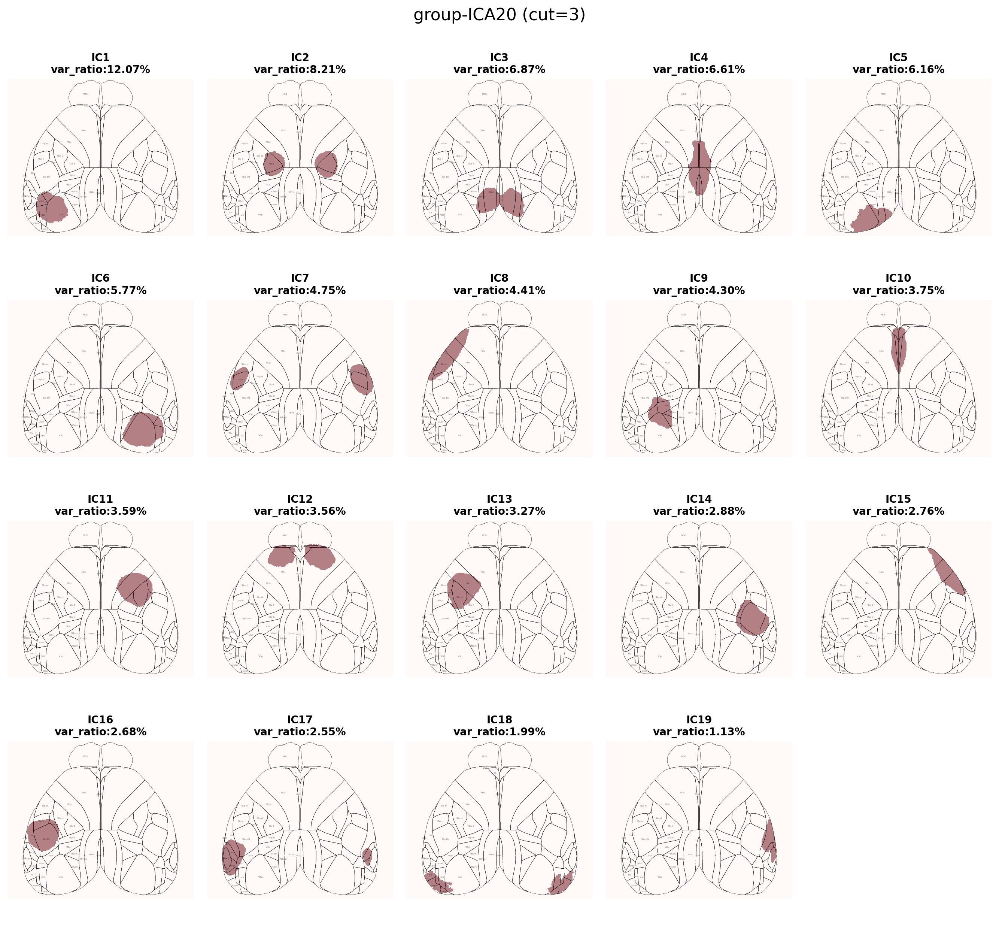

CPU times: user 9.72 s, sys: 168 ms, total: 9.89 s
Wall time: 9.96 s


In [98]:
# %%time
# # plot spatial IC

# ncol = 5
# nrow = n_IC//ncol
# dpi = 200

# fig, ax = plt.subplots(nrow, ncol, figsize=(warp_height / dpi * ncol, warp_width / dpi * nrow), dpi=dpi)
# for irow in range(nrow):
#     for icol in range(ncol):
#         iIC = irow * ncol + icol
#         if iIC==16:
#             ax[irow, icol].axis('off')
#             continue
#         if iIC>16:
#             img = ax[irow, icol-1].imshow(IC_arrayz_cut_cluster[iIC], cmap='Reds', clim=[0,1], alpha=0.5)
#             ax[irow, icol-1].set_title(f'IC{iIC}\nvar_ratio:{explained_variance_ratio[iIC]*100:.2f}%', fontsize=10)
#             ax[irow, icol-1].axis('off')
#             for idx, r in ccf_regions.iterrows():
#                 ax[irow, icol-1].plot(r['left_x'], r['left_y'], 'k', lw=0.2)
#                 ax[irow, icol-1].plot(r['right_x'], r['right_y'], 'k', lw=0.2)
#                 ax[irow, icol-1].text(r.left_center[0], r.left_center[1], r.acronym, color='k', va='center', fontsize=2,
#                                     alpha=0.5,
#                                     ha='center')
#         else:
#             img = ax[irow, icol].imshow(IC_arrayz_cut_cluster[iIC], cmap='Reds', clim=[0,1], alpha=0.5)
#             ax[irow, icol].set_title(f'IC{iIC + 1}\nvar_ratio:{explained_variance_ratio[iIC]*100:.2f}%', fontsize=10)
#             ax[irow, icol].axis('off')

#             for idx, r in ccf_regions.iterrows():
#                 ax[irow, icol].plot(r['left_x'], r['left_y'], 'k', lw=0.2)
#                 ax[irow, icol].plot(r['right_x'], r['right_y'], 'k', lw=0.2)
#                 ax[irow, icol].text(r.left_center[0], r.left_center[1], r.acronym, color='k', va='center', fontsize=2,
#                                     alpha=0.5,
#                                     ha='center')
#         ax[3,4].axis('off')
# fig.set_facecolor('white')
# fig.suptitle(f'group-ICA{n_IC} (cut={z_cut})', fontsize=16)
# plt.tight_layout(rect=[0, 0, 1, 0.99])
# plt.savefig(pjoin(path_out_gICA, f'group_ICA{n_IC}_cut{z_cut}_cluster_.png'), bbox_inches='tight', pad_inches=0)
# plt.show()



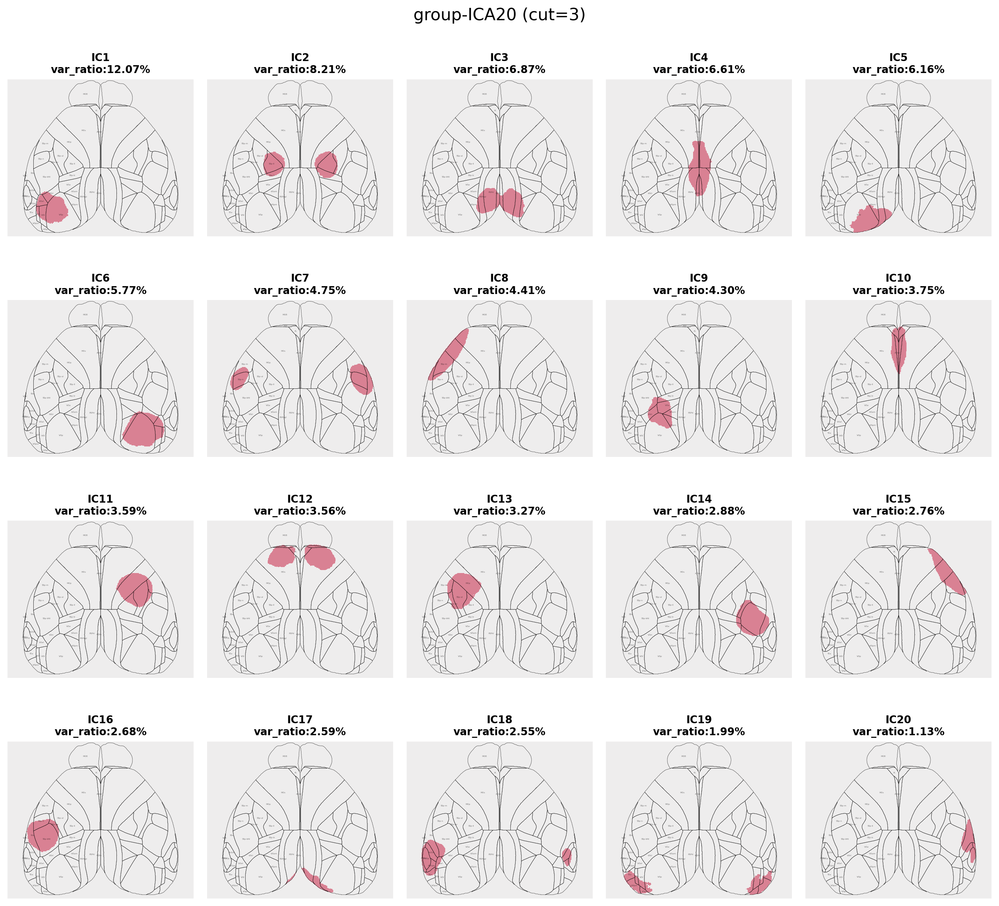

CPU times: user 10.1 s, sys: 458 ms, total: 10.6 s
Wall time: 10.7 s


In [234]:
%%time
# plot spatial IC

ncol = 5
nrow = n_IC//ncol
dpi = 200

fig, ax = plt.subplots(nrow, ncol, figsize=(warp_height / dpi * ncol, warp_width / dpi * nrow), dpi=dpi)
for irow in range(nrow):
    for icol in range(ncol):
        iIC = irow * ncol + icol
        # ax[irow, icol].imshow(frames_ave, cmap='gray')
        img = ax[irow, icol].imshow(IC_arrayz_cut_cluster[iIC], cmap='coolwarm', clim=[-1,1], alpha=0.5)
        ax[irow, icol].set_title(f'IC{iIC + 1}\nvar_ratio:{explained_variance_ratio[iIC]*100:.2f}%', fontsize=10)
        ax[irow, icol].axis('off')

        for idx, r in ccf_regions.iterrows():
            ax[irow, icol].plot(r['left_x'], r['left_y'], 'k', lw=0.2)
            ax[irow, icol].plot(r['right_x'], r['right_y'], 'k', lw=0.2)
            ax[irow, icol].text(r.left_center[0], r.left_center[1], r.acronym, color='k', va='center', fontsize=2,
                                alpha=0.5,
                                ha='center')
        # fig.colorbar(img)
fig.set_facecolor('white')
fig.suptitle(f'group-ICA{n_IC} (cut={z_cut})', fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig(pjoin(path_out_gICA, f'group_ICA{n_IC}_cut{z_cut}_cluster.png'), bbox_inches='tight', pad_inches=0)
plt.show()



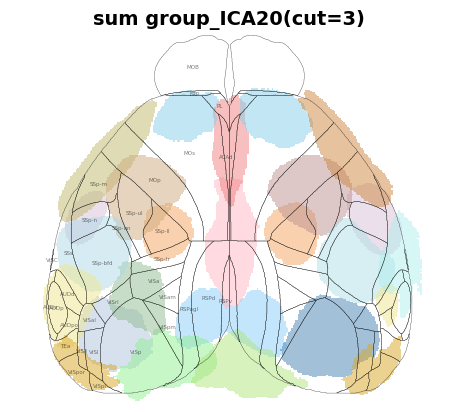

In [80]:
# plot superimposed spatial IC

from matplotlib.colors import ListedColormap

color_list = [
    "#B0C4DE", "#F4A460", "#87CEFA", "#FFB6C1", "#90EE90", "#4682B4", "#D8BFD8", 
    "#BDB76B", "#8FBC8F", "#F08080", "#BC8F8F", "#87CEEB", "#CDAA7D", "#B0E0E6", 
    "#CD853F", "#ADD8E6", "#B0E57C", "#F0E68C", "#DAA520", "#AFEEEE", "#DDA0DD", 
    "#A52A2A", "#8B4513", "#5F9EA0", "#F5DEB3", "#D2B48C", "#F4C2C2", "#E6E6FA", 
    "#EEE8AA", "#B4CDCD", "#FFE4B5", "#E0FFFF", "#DB7093", "#468499", "#FFD700", 
    "#40E0D0", "#FF6347", "#7FFFD4", "#FF7F50", "#9370DB", "#FF69B4", "#00CED1", 
    "#FFA07A", "#20B2AA", "#FF4500", "#FF8C00", "#6495ED", "#FF6347", "#4169E1", 
    "#DA70D6", "#98FB98", "#FF1493", "#32CD32", "#00FA9A", "#F08080", "#FFDAB9", 
    "#BA55D3", "#00FF7F", "#8A2BE2", "#4682B4", "#F5DEB3", "#00BFFF"
]



fig,ax = plt.subplots()

# 逐个叠加IC，使用不同颜色
for i in range(n_IC):
    cmap = ListedColormap(['None', color_list[i]])
    plt.imshow(IC_arrayz_cut_cluster[i], cmap=cmap, interpolation='nearest', alpha=0.5)

for i, r in ccf_regions.iterrows():
    plt.plot(r['left_x'], r['left_y'], 'k', lw=0.2)
    plt.plot(r['right_x'], r['right_y'], 'k', lw=0.2)
    plt.text(r.left_center[0], r.left_center[1], r.acronym, color='k', va='center', fontsize=4, alpha=0.5, ha='center')

# plot_borders(retino['finalPatchesMarked'], plotAxis=ax, title=None, zoom=1,
#                  borderWidth=1, isColor=True, plotName=True, fontSize=7)

plt.axis('off')
fig.set_facecolor('white')
plt.title(f'sum group_ICA{n_IC}(cut={z_cut})')
plt.savefig(pjoin(path_out_gICA, f'sum group_ICA{n_IC}_cut{z_cut}.png'), bbox_inches='tight', pad_inches=0)
plt.show()

## select ICs

In [9]:
select_IC_index = [0, 1, 2, 3, 4, 5, 6, 8, 9,10,11,12,13,15,17]
select_IC = IC_arrayz_cut_cluster[select_IC_index]
select_nIC = len(select_IC_index)
IC_list = ['IC'+str(i) for i in range(1,select_nIC+1)]

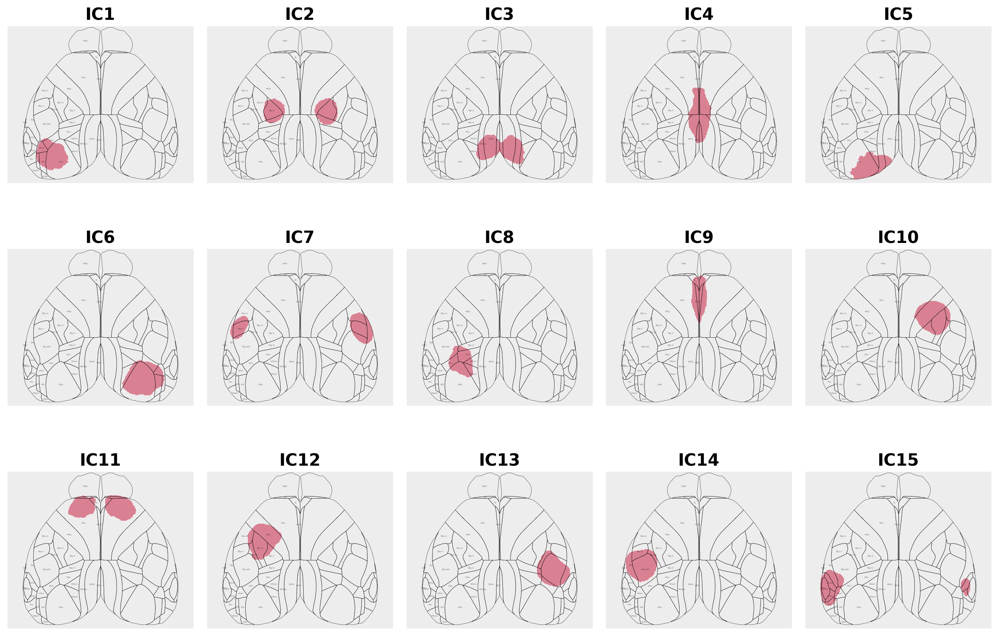

CPU times: user 7.15 s, sys: 185 ms, total: 7.33 s
Wall time: 7.36 s


In [143]:
%%time


# plot spatial IC

ncol = 5
nrow = 3
dpi = 200

fig, ax = plt.subplots(nrow, ncol, figsize=(warp_height / dpi * ncol, warp_width / dpi * nrow), dpi=dpi)
for irow in range(nrow):
    for icol in range(ncol):
        iIC = irow * ncol + icol
        # ax[irow, icol].imshow(frames_ave, cmap='gray')
        img = ax[irow, icol].imshow(select_IC[iIC], cmap='coolwarm', clim=[-1,1], alpha=0.5)
        ax[irow, icol].set_title(f'IC{iIC + 1}', fontsize=16)

        ax[irow, icol].axis('off')

        for idx, r in ccf_regions.iterrows():
            ax[irow, icol].plot(r['left_x'], r['left_y'], 'k', lw=0.2)
            ax[irow, icol].plot(r['right_x'], r['right_y'], 'k', lw=0.2)
            ax[irow, icol].text(r.left_center[0], r.left_center[1], r.acronym, color='k', va='center', fontsize=2,
                                alpha=0.5,
                                ha='center')
        # fig.colorbar(img)
fig.set_facecolor('white')
# fig.suptitle(f'selected ICs', fontsize=24)
plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig(pjoin(path_out_gICA, f'selected ICs.png'), bbox_inches='tight', pad_inches=0)
plt.show()



In [16]:
import numpy as np
import pandas as pd


def summarize_IC_area_overlap(binary_IC_array,atlas,areanames,outfile=None):
    """
    Parameters
    ----------
    binary_IC_array : ndarray
        shape = (n_IC, H, W), binary (bool or 0/1)
    atlas : ndarray
        shape = (H, W), int, pixel-wise area id
    areanames : array-like or list
        shape = (n_area, 2), [area_id, area_name]
    outfile : str or None
        if not None, write csv to this path

    Returns
    -------
    df : pandas.DataFrame
        summary table
    """

    area_ids = np.asarray(areanames)[:, 0].astype(int)
    area_name_map = {int(row[0]): row[1] for row in areanames}

    # precompute area sizes
    area_pixel_count = {aid: np.sum(atlas == aid) for aid in area_ids}

    records = []
    n_IC = binary_IC_array.shape[0]

    for ic_idx in range(n_IC):
        ic_mask = binary_IC_array[ic_idx].astype(bool)
        ic_area = np.sum(ic_mask)

        if ic_area == 0:
            continue

        overlapping_areas = np.unique(atlas[ic_mask])

        area_stats = []

        for aid in overlapping_areas:
            if aid not in area_pixel_count:
                continue

            area_area = area_pixel_count[aid]
            if area_area == 0:
                continue

            overlap = np.sum(ic_mask & (atlas == aid))
            if overlap == 0:
                continue

            frac_ic = overlap / ic_area
            frac_area = overlap / area_area
            score = frac_ic * frac_area

            area_stats.append({
                "IC": ic_idx,
                "Area_ID": aid,
                "Area_Name": area_name_map.get(aid, "Unknown"),
                "Overlap_frac_of_IC": frac_ic,
                "Overlap_frac_of_Area": frac_area,
                "Score": score
            })

        if len(area_stats) == 0:
            continue

        # ---- 强制保留 overlap / IC 最大的脑区 ----
        area_stats = sorted(
            area_stats,
            key=lambda x: x["Overlap_frac_of_IC"],
            reverse=True
        )

        primary_area = area_stats[0]
        records.append(primary_area)

        # ---- 其余脑区按 score > 0.1 ----
        for entry in area_stats[1:]:
            if entry["Score"] > 0.1:
                records.append(entry)

    df = pd.DataFrame(records)

    if len(df) > 0:
        df = df.sort_values(
            by=["IC", "Overlap_frac_of_IC"],
            ascending=[True, False]
        )

    if outfile is not None:
        df.to_csv(outfile, index=False)
        print(f"Saved: {outfile}")

    print(df)
    return df


In [19]:

df_overlap = summarize_IC_area_overlap(select_IC,atlas,areanames,
                outfile=pjoin(path_out_gICA,"IC_area_overlap_summary.csv"))

Saved: /home/lzx/data/WF_VC_liuzhaoxi/______________natural_movie_group_ICA/IC_area_overlap_summary.csv
    IC  Area_ID      Area_Name  Overlap_frac_of_IC  Overlap_frac_of_Area  \
0    0     33.0      VISp_left            0.635512              0.467945   
1    1    -17.0   SSp-ll_right            0.265619              0.981586   
2    1     17.0    SSp-ll_left            0.263607              0.974841   
3    2     11.0      RSPd_left            0.277997              0.476942   
4    2    -11.0     RSPd_right            0.275545              0.472735   
5    3     -4.0      MOs_right            0.237807              0.144583   
6    4     33.0      VISp_left            0.676868              0.463318   
7    5    -33.0     VISp_right            0.724361              0.782078   
8    6     -5.0    SSp-n_right            0.226732              1.000000   
9    6      5.0     SSp-n_left            0.209098              0.920533   
10   7     33.0      VISp_left            0.314179          

## group ICA timecourse

In [20]:
from skimage.transform import warp
n_IC = 20
warped_height, warped_width = (540, 640)
path_out_gICA = r'/home/lzx/data/WF_VC_liuzhaoxi/______________natural_movie_group_ICA/'
warped_height, warped_width = (540, 640)

ccf_regions_reference,proj,brain_outline = allen_load_reference('dorsal_cortex')
lmarks = load_allen_landmarks(None)
ccf_regions = allen_transform_regions(None,ccf_regions_reference,
              resolution = lmarks['resolution'],bregma_offset = lmarks['bregma_offset'])
atlas, areanames, brain_mask = atlas_from_landmarks_file(landmarks_file=None, 
              reference='dorsal_cortex', dims = [warped_height, warped_width], do_transform = None) 
              
IC_array = np.load(pjoin(path_out_gICA, f'group_ICA{n_IC}.npy'))
mix_matrix = np.load(pjoin(path_out_gICA, f'group_ICA{n_IC}_mix.npy'))
VTsum = np.load(pjoin(path_out_gICA,'VTsum.npy'))

print('IC_array.shape', IC_array.shape,
"\nmix_matrix.shape", mix_matrix.shape, 
"\nVTsum.shape:", VTsum.shape)

IC_array.shape (20, 540, 640) 
mix_matrix.shape (7400, 20) 
VTsum.shape: (37, 200, 14000)


In [21]:
n_frame = 150  # 帧
pre_length = 20
after_length = 30
trial_length = n_frame+pre_length+after_length
movie_list = pd.read_csv(pjoin(r'/home/lzx/data/WF_VC_liuzhaoxi/25.01.12_U27/natural-movie/raw/natural_movies', 'movie_list.txt'), header=None).values
n_movie = movie_list.size
movie_name_list = []
for imovie in range(n_movie):
    mv_name = str(movie_list[imovie])[2:-6]
    if mv_name[-1].isdigit():
        mv_name = mv_name[:-1]
    movie_name_list.append(mv_name.lower())
n_rep = VTsum.shape[-1]//(n_movie*trial_length)
n_experiment, n_svd = VTsum.shape[:2]


In [79]:
mix_matrix = mix_matrix.reshape(n_experiment,n_svd,n_IC)

Timecourse_sum = np.einsum(
    'esi,est->eit', 
    mix_matrix, # [svd,experiment,IC]
    VTsum) # [experiment,svd,frame]

Timecourse_sum.shape

(37, 20, 14000)

In [80]:
IC_array_scaled=np.empty_like(IC_array)
Timecourse_scaled=np.empty_like(Timecourse_sum)
for i_IC in range(n_IC):
    scale = np.linalg.norm(IC_array[i_IC])
    IC_array_scaled[i_IC] = IC_array[i_IC]/scale
    Timecourse_scaled[:,i_IC] = Timecourse_sum[:,i_IC]*scale

Timecourse_scaled = Timecourse_scaled.reshape(n_experiment,n_IC,trial_length,n_movie,n_rep).transpose(1,2,3,4,0)
Timecourse_scaled.shape
# [n_IC,trial_length,n_movie,n_rep,n_experiment]

(20, 200, 14, 5, 37)

In [89]:
ic_negtive = Timecourse_scaled.mean((1,2,3,4)) < 0
Timecourse_scaled[ic_negtive] = -1 * Timecourse_scaled[ic_negtive] # 确保IC方向为正
IC_array_scaled[ic_negtive] = -1 * IC_array_scaled[ic_negtive]

In [91]:
np.save(pjoin(path_out_gICA, f'group_ICA{n_IC}_scaled.npy'), IC_array_scaled)
np.save(pjoin(path_out_gICA, f'group_ICA{n_IC}_timecourse_sum_scaled.npy'), Timecourse_scaled)

In [218]:

Timecourse_scaled = np.delete(Timecourse_scaled, 28, axis=-1)
np.save(pjoin(path_out_gICA, f'group_ICA{n_IC}_timecourse_scaled.npy'), Timecourse_scaled)
Timecourse_scaled.shape

(20, 200, 14, 5, 36)

In [200]:
# plot all IC timecourse

# data.shape = [n_patch, n_movie, timecourse, n_rep]
subplot_timecourse(Timecourse_scaled.reshape(n_IC,trial_length,n_movie,-1).transpose(0,2,1,3), list(range(1,n_IC+1)), movie_name_list, title=f'group_ICA{n_IC}_timecourse', outpath=path_out_gICA, pre_length=20, n_frame=150, plot_rep=False, dpi=200)


## SNR

In [28]:
def plot_heatmap(data, xlabel=None, ylabel=None, xtitle=None, ytitle=None, cmap='coolwarm', colorbar_name=None, 
                 vmin=None, vmax=None, center=None, title=None, outfile=None, dpi=300, annot=True):
    import seaborn as sns
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(int(data.shape[1]//1.3), int(data.shape[0])//1.3))
    fig.set_facecolor('white')
    # 使用seaborn的heatmap函数来绘制热图
    sns.heatmap(data, cmap=cmap, vmin=vmin, vmax=vmax, center=center, annot=annot, fmt=".2f", annot_kws={"size": 14, "color": 'black'},
                ax=ax, cbar=True, square=True, linewidths=0, cbar_kws={'fraction': 0.038, 'pad': 0.03})
    cbar = ax.collections[0].colorbar 
    cbar.ax.tick_params(labelsize=24) # 设置colorbar刻度标签的字号 
    if colorbar_name is not None:
        cbar.ax.set_title(colorbar_name, fontsize=23, pad=20, loc="left", fontweight="normal")

    if xtitle is not None:
        ax.set_xlabel(xtitle, fontsize=18)
    if xlabel is not None:
        # ax.set_xticklabels(xlabel, rotation=45, ha='right', fontsize=15)
        ax.set_xticklabels(xlabel, fontsize=20, rotation=90)

    if ytitle is not None:
        ax.set_ylabel(ytitle, fontsize=18)
    if ylabel is not None:
        ax.set_yticklabels(ylabel, rotation=0, fontsize=20)
    plt.gca().invert_yaxis()  # 倒置y轴

    if title:
        ax.set_title(title, fontsize=30)
    if outfile:
        plt.savefig(outfile, bbox_inches='tight', dpi=dpi)

    plt.show()



In [26]:
Timecourse_scaled = np.load(pjoin(path_out_gICA, f'group_ICA{n_IC}_timecourse_scaled.npy'))
Timecourse_scaled.shape

(20, 200, 14, 5, 36)

In [27]:
select_Timecourse=Timecourse_scaled[select_IC_index]
select_Timecourse.shape

(15, 200, 14, 5, 36)

In [28]:
## cal all snr
snr_array = cal_snr(select_Timecourse, axis1=3, axis2=1)
print('snr_array.shape', snr_array.shape)
np.save(pjoin(path_out_gICA,'all_snr.npy'), snr_array)



snr_array.shape (15, 14, 36)


In [29]:
snr_array = np.load(pjoin(path_out_gICA,'all_snr.npy'))
snr_array.shape

(15, 14, 36)

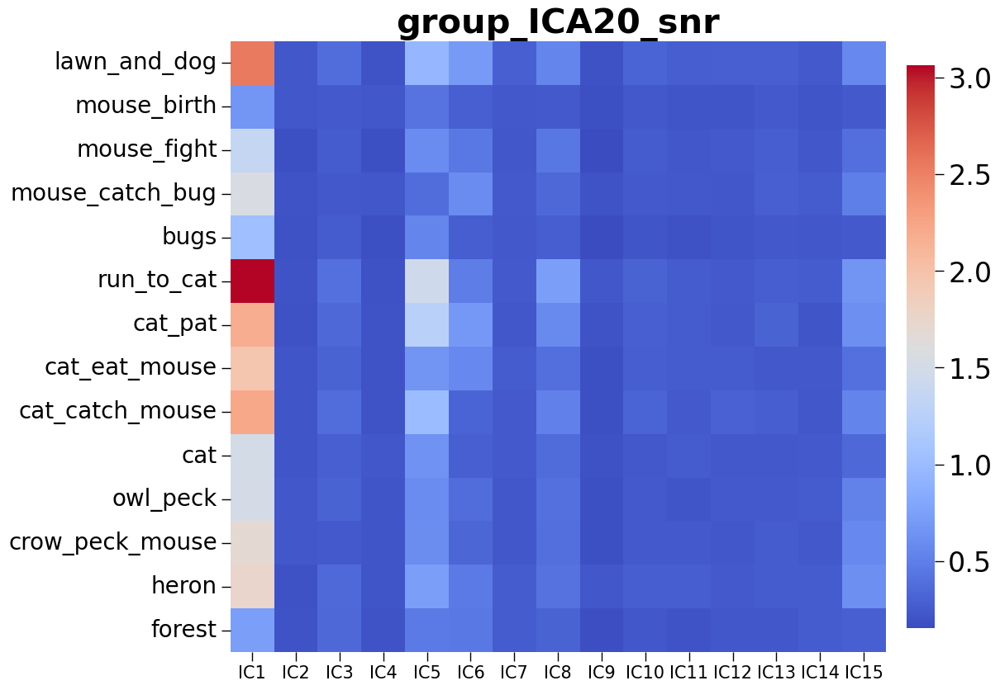

In [131]:
plot_heatmap(np.nanmean(snr_array,axis=-1).T, xlabel=IC_list, ylabel=movie_name_list, cmap='coolwarm', 
             vmin=None, vmax=None, title=f'group_ICA{n_IC}_snr', 
             outfile=pjoin(path_out_gICA,f'ICA{n_IC} mean snr.png'), dpi=300, annot=False)


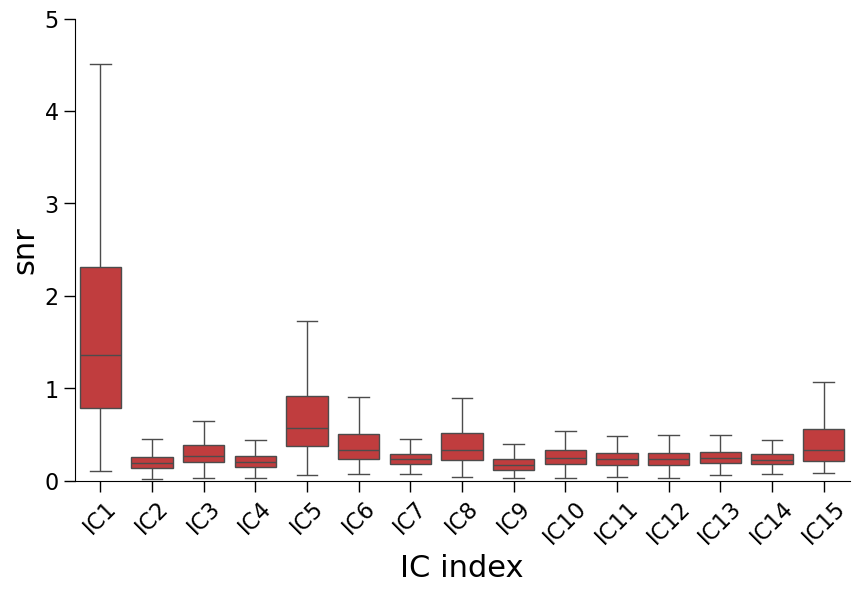

In [96]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 将矩阵转换为 DataFrame
df = pd.DataFrame(snr_array.reshape(select_nIC, -1).T, columns=IC_list)

# 将数据转换为长格式
df_long = df.melt(var_name='IC', value_name='snr')

# 按每组的平均值对分组排序
group_order = df.mean(axis=0).sort_values(ascending=False).index

plt.figure(figsize=(10, 6))
sns.boxplot(x='IC', y='snr', data=df_long, order=None, color='tab:red',showfliers = False)
# sns.violinplot(x='IC', y='snr', data=df_long, order=None, density_norm='width', inner='quartile', color='tab:red')   # 绘制小提琴图
# plt.title('IC snr')
plt.xlabel('IC index', fontsize=22)
plt.ylabel('snr', fontsize=22)
plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)
plt.ylim(0,5)
fig = plt.gcf()  # 获取当前图形对象
fig.set_facecolor('white')  # 设置背景为白色
plt.savefig(pjoin(path_out_gICA, 'all IC snr boxplot.png'), facecolor='white', transparent=False, bbox_inches='tight')
plt.show()


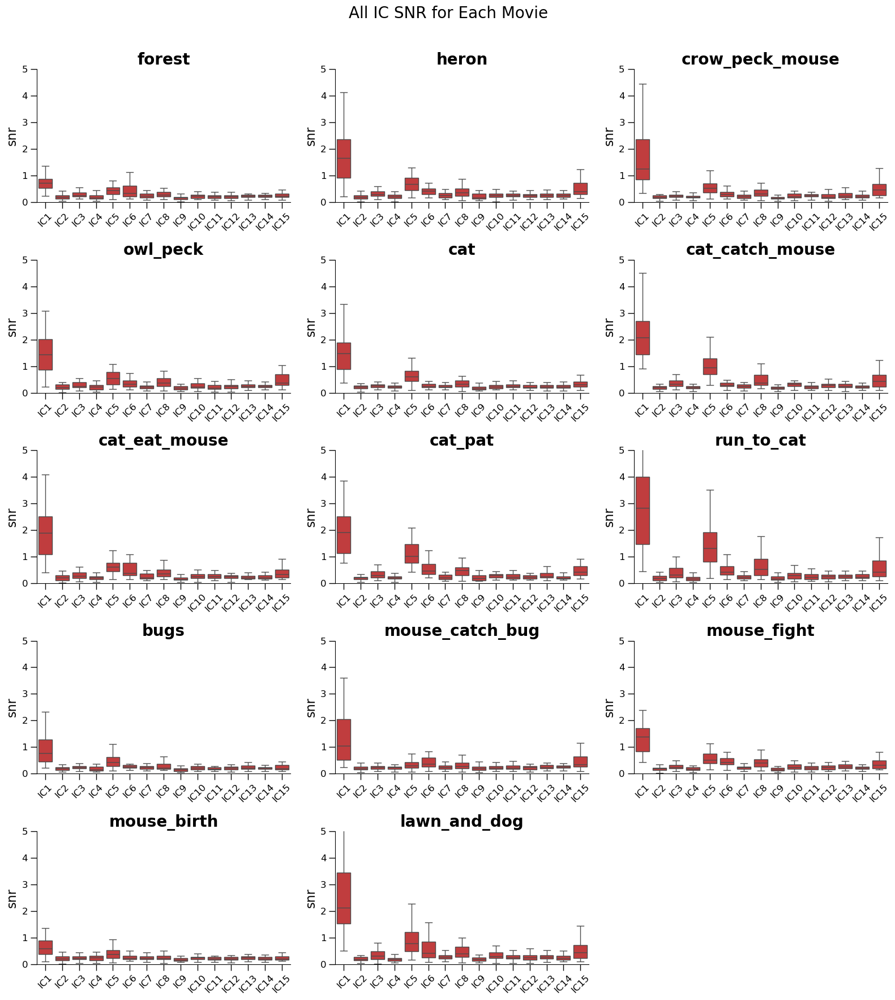

In [45]:
# 创建子图
fig, axes = plt.subplots(5, 3, figsize=(16, 18))
axes = axes.flatten()  # 将 axes 二维数组展平，便于迭代
for i in range(n_movie):  # 遍历第三维的每个小图
    # 提取当前小图对应的数据
    matrix = snr_array[:, i, :]
    df = pd.DataFrame(matrix.T, columns=IC_list)
    
    # 转换为长格式
    df_long = df.melt(var_name='IC', value_name='snr')

    sns.boxplot(x='IC', y='snr', data=df_long, order=None, ax=axes[i], color='tab:red',showfliers=False)
    # sns.violinplot(x='IC', y='snr', data=df_long, order=None, ax=axes[i], density_norm='width', inner='quartile', color='tab:red')     # 绘制小提琴图
    axes[i].set_title(movie_name_list[i], fontsize=20)  # 设置小标题
    axes[i].set_xlabel('')  # 隐藏 x 轴标签以节省空间
    axes[i].set_ylabel('snr', fontsize=16)
    axes[i].set_ylim(0, 5)  # 设置统一 y 轴范围
    axes[i].tick_params(axis='x', rotation=45, labelsize=12)  # 调整刻度角度和字体大小
    axes[i].tick_params(axis='y', labelsize=12)  # 调整刻度角度和字体大小

    # for label in axes[i].get_xticklabels():
    #     label.set_ha('right')  # 设置 x 轴标签右对齐

# 删除多余的子图（仅 14 个小图）
for j in range(14, len(axes)):
    fig.delaxes(axes[j])

# 设置整体标题和布局
fig.suptitle('All IC SNR for Each Movie', fontsize=20)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.set_facecolor('white')  # 设置背景为白色

# 保存图像
plt.savefig(pjoin(path_out_gICA, 'all_IC_snr_per_movie_boxplot.png'), facecolor='white', transparent=False)
plt.show()


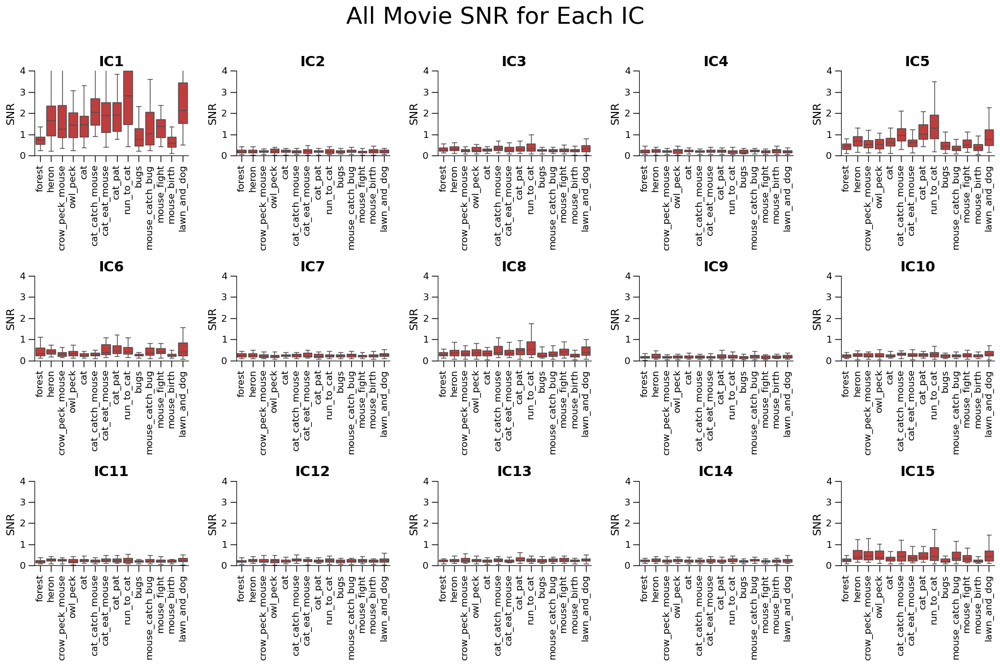

In [48]:

# 创建子图
fig, axes = plt.subplots(3, 5, figsize=(18, 12))
axes = axes.flatten()  # 将子图展平成一维数组，方便迭代

for i_IC in range(select_nIC):  # 遍历20个IC
    # 提取当前脑区的数据
    data = snr_array[i_IC].T  # (重复数, 视频数)
    df = pd.DataFrame(data, columns=movie_name_list)  # 将视频作为列
    df_long = df.melt(var_name='Movies', value_name='SNR')  # 转为长格式
    
    sns.boxplot(x='Movies', y='SNR', data=df_long, ax=axes[i_IC], color='tab:red',showfliers=False)
    axes[i_IC].set_title(IC_list[i_IC],fontsize=18)  # 设置小标题为脑区名
    axes[i_IC].set_xlabel('')  # 隐藏 x 轴标签
    axes[i_IC].set_ylabel('SNR', fontsize=14)  # y 轴标签保持为 SNR
    axes[i_IC].set_ylim(0,4)
    axes[i_IC].tick_params(axis='x', rotation=90, labelsize=12)  # 设置刻度字体大小
    axes[i_IC].tick_params(axis='y', labelsize=12)  

    # for label in axes[idx].get_xticklabels():
    #     label.set_ha('right')  # 设置 x 轴标签右对齐


# 设置整体标题和布局
fig.suptitle('All Movie SNR for Each IC', fontsize=30)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.set_facecolor('white')  # 设置背景为白色

# 保存图像
plt.savefig(pjoin(path_out_gICA, 'all_movie_snr_per_IC boxplot.png'), facecolor='white', transparent=False)
plt.show()


## std

In [49]:
## cal all std

std_array = np.nanstd(select_Timecourse, axis=(1,3))
print('std_array.shape', snr_array.shape)
np.save(pjoin(path_out_gICA,'all_std.npy'), std_array)

std_array.shape (15, 14, 36)


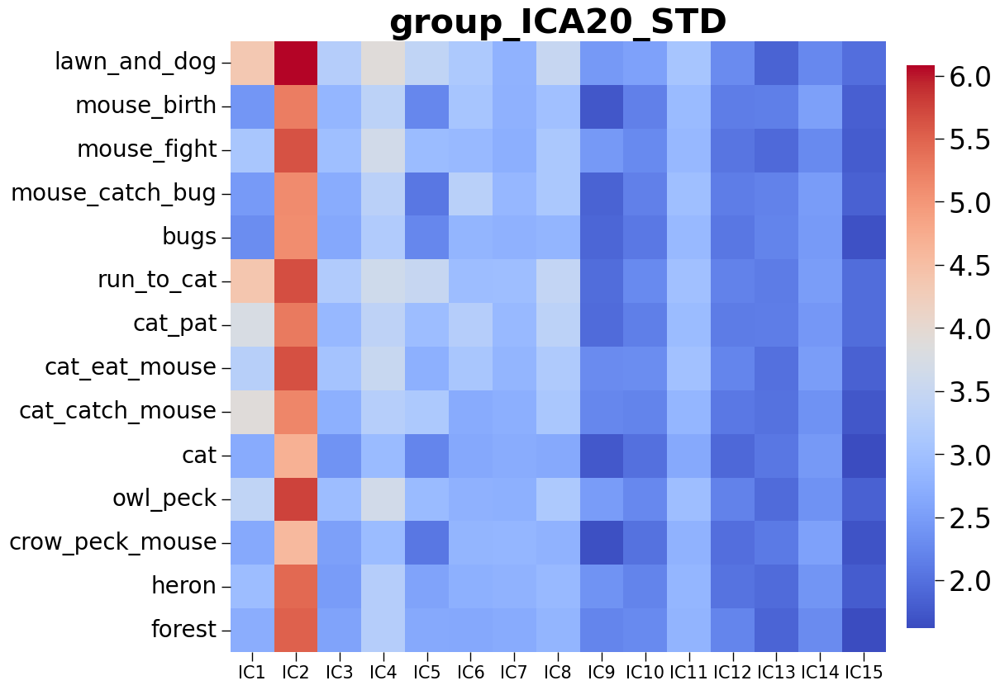

In [132]:
plot_heatmap(np.nanmean(std_array,axis=-1).T, xlabel=IC_list, ylabel=movie_name_list, cmap='coolwarm', 
             vmin=None, vmax=None, title=f'group_ICA{n_IC}_STD', 
             outfile=pjoin(path_out_gICA,f'ICA{n_IC} mean std.png'), dpi=300, annot=False)


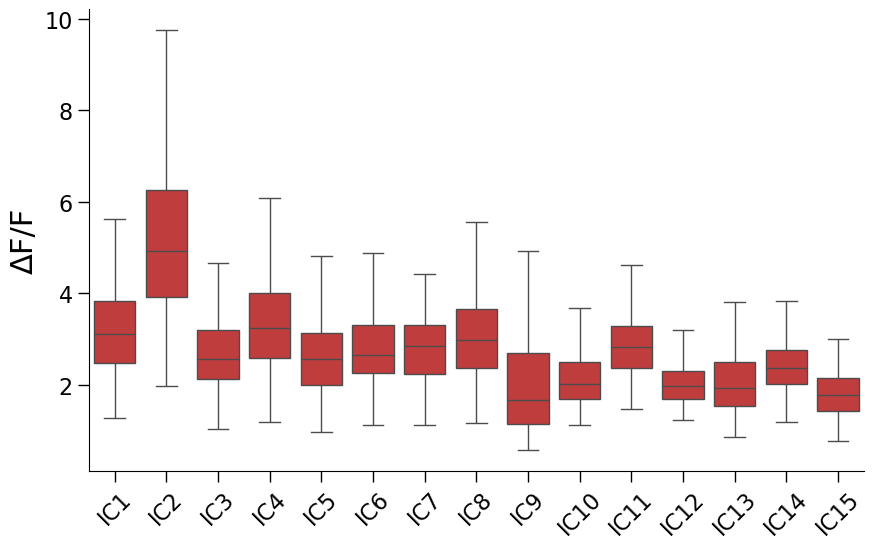

In [152]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 将矩阵转换为 DataFrame
df = pd.DataFrame(std_array.reshape(select_nIC, -1).T, columns=IC_list)

# 将数据转换为长格式
df_long = df.melt(var_name='IC', value_name='std')

# 按每组的平均值对分组排序
group_order = df.mean(axis=0).sort_values(ascending=False).index

plt.figure(figsize=(10, 6))
sns.boxplot(x='IC', y='std', data=df_long, order=None, color='tab:red',showfliers = False)
# plt.title('IC std')
plt.xlabel(None)
plt.ylabel('ΔF/F', fontsize=22)
plt.xticks(rotation=45, fontsize=16)
plt.yticks(fontsize=16)

# plt.ylim(0,5)
fig = plt.gcf()  # 获取当前图形对象
fig.set_facecolor('white')  # 设置背景为白色
plt.savefig(pjoin(path_out_gICA, 'all IC std boxplot.png'), facecolor='white', transparent=False, bbox_inches='tight')
plt.show()


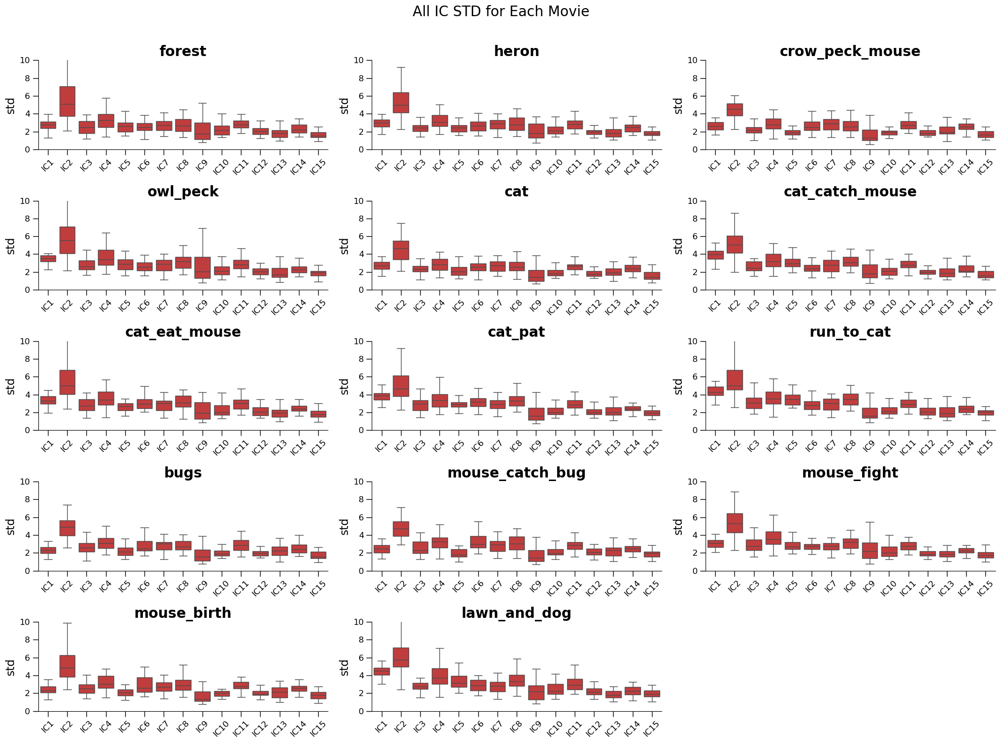

In [53]:
# 创建子图
fig, axes = plt.subplots(5, 3, figsize=(20, 15))
axes = axes.flatten()  # 将 axes 二维数组展平，便于迭代
for i in range(n_movie):  # 遍历第三维的每个小图
    # 提取当前小图对应的数据
    matrix = std_array[:, i, :]
    df = pd.DataFrame(matrix.T, columns=IC_list)
    
    # 转换为长格式
    df_long = df.melt(var_name='IC', value_name='std')

    sns.boxplot(x='IC', y='std', data=df_long, order=None, ax=axes[i], color='tab:red',showfliers=False)
    # sns.violinplot(x='IC', y='snr', data=df_long, order=None, ax=axes[i], density_norm='width', inner='quartile', color='tab:red')     # 绘制小提琴图
    axes[i].set_title(movie_name_list[i], fontsize=20)  # 设置小标题
    axes[i].set_xlabel('')  # 隐藏 x 轴标签以节省空间
    axes[i].set_ylabel('std', fontsize=16)
    axes[i].set_ylim(0, 10)  # 设置统一 y 轴范围
    axes[i].tick_params(axis='x', rotation=45, labelsize=12)  # 调整刻度角度和字体大小
    axes[i].tick_params(axis='y', labelsize=12)  
    # for label in axes[i].get_xticklabels():
    #     label.set_ha('right')  # 设置 x 轴标签右对齐

# 删除多余的子图（仅 14 个小图）
for j in range(14, len(axes)):
    fig.delaxes(axes[j])

# 设置整体标题和布局
fig.suptitle('All IC STD for Each Movie', fontsize=20)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.set_facecolor('white')  # 设置背景为白色

# 保存图像
plt.savefig(pjoin(path_out_gICA, 'all_IC_std_per_movie_boxplot.png'), facecolor='white', transparent=False)
plt.show()


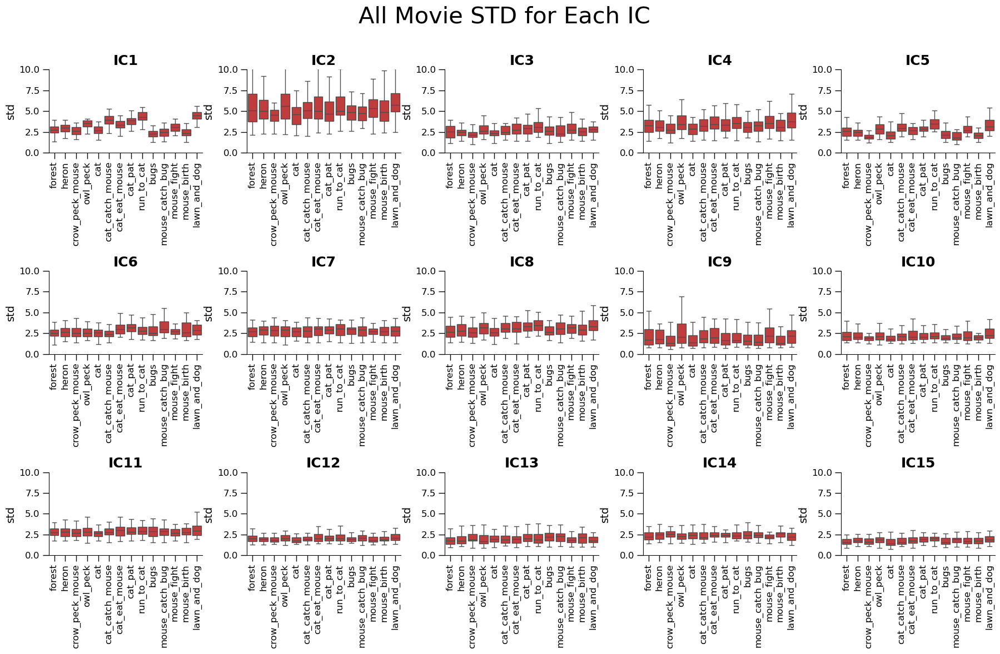

In [54]:

# 创建子图
fig, axes = plt.subplots(3, 5, figsize=(18, 12))
axes = axes.flatten()  # 将子图展平成一维数组，方便迭代

for i_IC in range(select_nIC):  # 遍历20个IC
    # 提取当前脑区的数据
    data = std_array[i_IC].T  # (重复数, 视频数)
    df = pd.DataFrame(data, columns=movie_name_list)  # 将视频作为列
    df_long = df.melt(var_name='Movies', value_name='std')  # 转为长格式
    
    sns.boxplot(x='Movies', y='std', data=df_long, ax=axes[i_IC], color='tab:red',showfliers=False)
    axes[i_IC].set_title(IC_list[i_IC],fontsize=18)  # 设置小标题为脑区名
    axes[i_IC].set_xlabel('')  # 隐藏 x 轴标签
    axes[i_IC].set_ylabel('std', fontsize=14)  # y 轴标签保持为 SNR
    axes[i_IC].set_ylim(0,10)
    axes[i_IC].tick_params(axis='x', rotation=90, labelsize=12)  # 设置刻度字体大小
    axes[i_IC].tick_params(axis='y', labelsize=12)  

    # for label in axes[idx].get_xticklabels():
    #     label.set_ha('right')  # 设置 x 轴标签右对齐


# 设置整体标题和布局
fig.suptitle('All Movie STD for Each IC', fontsize=30)
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.set_facecolor('white')  # 设置背景为白色

# 保存图像
plt.savefig(pjoin(path_out_gICA, 'all_movie_std_per_IC boxplot.png'), facecolor='white', transparent=False)
plt.show()



## IC correlation

In [58]:
from scipy.signal import correlate

def compute_lag_correlation(matrix, max_lag=None):
    """
    计算矩阵中每一行之间的归一化 lag correlation 和限制范围内的滞后。

    参数:
        matrix (numpy.ndarray): 输入二维矩阵，形状为 (n_rows, n_cols)
        max_lag (int): 限制的最大滞后帧数。如果为 None，则搜索全时程。

    返回:
        max_corr_matrix (numpy.ndarray): 最大绝对值相关性矩阵
        max_lag_matrix (numpy.ndarray): 最大相关性对应的滞后矩阵
    """
    n_rows = matrix.shape[0]
    n_cols = matrix.shape[1]
    max_corr_matrix = np.zeros((n_rows, n_rows))
    max_lag_matrix = np.zeros((n_rows, n_rows))

    # 互相关结果的全长度为 2*n_cols - 1，中心索引（即 lag=0）在 n_cols - 1
    center_idx = n_cols - 1

    for i in range(n_rows):
        for j in range(i, n_rows):  # 只计算上三角矩阵以提高效率
            # 提取信号并去均值
            x = matrix[i]
            y = matrix[j]
            x = x - np.nanmean(x)
            y = y - np.nanmean(y)
            
            # 计算全量 cross-correlation
            corr = correlate(x, y, mode='full', method='auto')
            
            # 归一化因子
            normalization_factor = np.nanstd(x) * np.nanstd(y) * n_cols
            if normalization_factor == 0:
                corr_norm = corr
            else:
                corr_norm = corr / normalization_factor 
            
            # 限制滞后范围
            if max_lag is not None:
                # 定义搜索窗口的起止索引
                start_idx = max(0, center_idx - max_lag)
                end_idx = min(len(corr_norm), center_idx + max_lag + 1)
                
                # 对相关性数组进行切片
                search_window = corr_norm[start_idx:end_idx]
                
                # 在窗口内寻找最大绝对值相关性
                relative_max_idx = np.argmax(np.abs(search_window))
                max_corr = search_window[relative_max_idx]
                
                # 将窗口内的相对索引转换回原始的全局 lag
                lag = (start_idx + relative_max_idx) - center_idx
            else:
                # 不限制范围，搜索全时程（原逻辑）
                max_corr_idx = np.argmax(np.abs(corr_norm))
                max_corr = corr_norm[max_corr_idx]
                lag = max_corr_idx - center_idx
            
            # 填入矩阵
            max_corr_matrix[i, j] = max_corr
            max_corr_matrix[j, i] = max_corr
            max_lag_matrix[i, j] = lag
            max_lag_matrix[j, i] = -lag  # 滞后是互为相反数的

    return max_corr_matrix, max_lag_matrix

IC_corr = np.zeros((n_experiment-1, select_nIC, select_nIC))
IC_lag = np.zeros((n_experiment-1, select_nIC, select_nIC))
for i_exp in range(n_experiment-1):
    Timecourse1 = select_Timecourse[:,:,:, :,i_exp].reshape(select_nIC, -1)
    IC_corr[i_exp], IC_lag[i_exp] = compute_lag_correlation(Timecourse1, max_lag=30)

# Timecourse1 = select_Timecourse.mean((-2,-1)).reshape(n_IC, -1)
# IC_corr, IC_lag = compute_lag_correlation(Timecourse1, max_lag=30)
np.save(pjoin(path_out_gICA,f'IC correlation.npy'), IC_corr)
np.save(pjoin(path_out_gICA,f'IC correlation lag.npy'), IC_lag)
print('IC_corr.shape', IC_corr.shape)

IC_corr.shape (36, 15, 15)


In [4]:
IC_corr = np.load(pjoin(path_out_gICA,f'IC correlation.npy'))
IC_lag = np.load(pjoin(path_out_gICA,f'IC correlation lag.npy'))

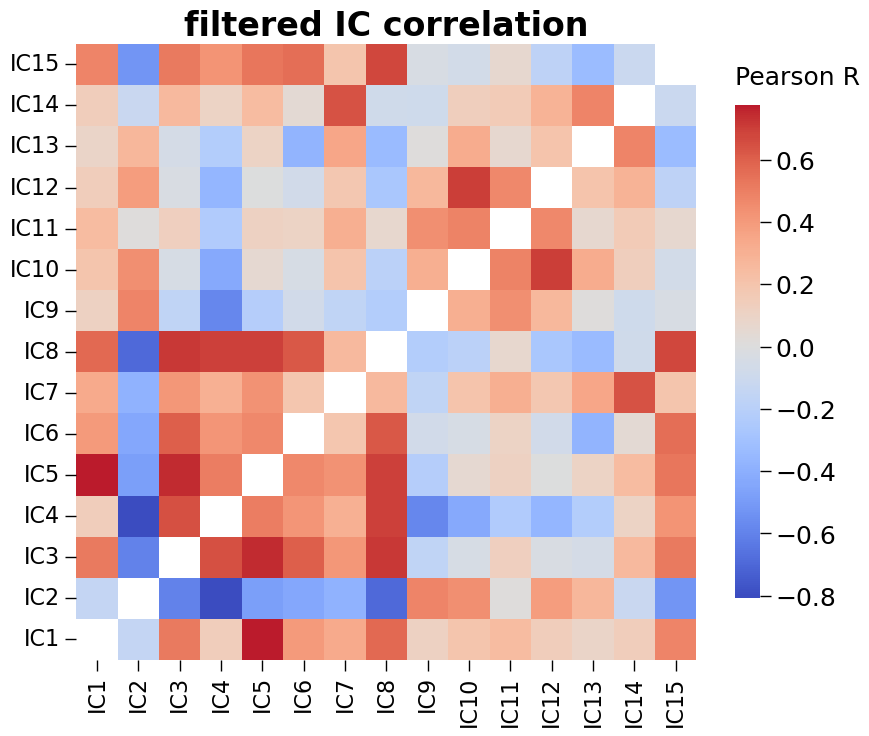

In [24]:
def plot_masked_correlation(IC_corr, IC_lag, max_lag_frames, out_file=None):
    """
    绘制相关性热图，并将达到 lag 边界的不可靠连接置白。
    """
    # 1. 创建 Mask 矩阵：如果 lag 的绝对值等于 max_lag，则判定为不可靠
    # 允许 1 帧的容错，或者直接用 np.abs(IC_lag) >= max_lag_frames
    unreliable_mask = np.abs(IC_lag) >= max_lag_frames-1
    
    # 对角线通常也建议 mask 掉，因为自相关总是 1 且 lag 为 0
    diag_mask = np.eye(IC_corr.shape[0], dtype=bool)
    final_mask = unreliable_mask | diag_mask

    fig=plt.figure(figsize=(10, 8))
    # 使用 seaborn 绘图，mask 参数会将 True 的位置留白
    sns.heatmap(IC_corr, mask=final_mask, annot=False, fmt=".2f", 
                cmap='coolwarm', center=0,annot_kws={"size": 5}, cbar_kws={"shrink": 0.8})
    cbar = plt.gca().collections[0].colorbar
    cbar.ax.set_title("Pearson R", fontsize=18, pad=15, loc="left", fontweight="normal")
    cbar.ax.tick_params(labelsize=18) 
    plt.title(f'filtered IC correlation', fontsize=24)
    plt.gca().invert_yaxis()  # 倒置y轴
    # plt.xlabel('IC Index')
    # plt.ylabel('IC Index')
    plt.xticks(ticks=np.arange(0.5, select_nIC+0.5), labels=IC_list, rotation=90, fontsize=16)
    plt.yticks(ticks=np.arange(0.5, select_nIC+0+0.5), labels=IC_list, rotation=0, fontsize=16)
    fig.set_facecolor('white')
    if out_file:
        plt.savefig(out_file, bbox_inches='tight', pad_inches=0, dpi=300)
    plt.show()

# plot_masked_correlation(IC_corr, IC_lag, max_lag_frames=30)
plot_masked_correlation(IC_corr.mean(0), IC_lag.mean(0), max_lag_frames=30, 
                        out_file=pjoin(path_out_gICA,'timecourse',f'IC correlation.png'))

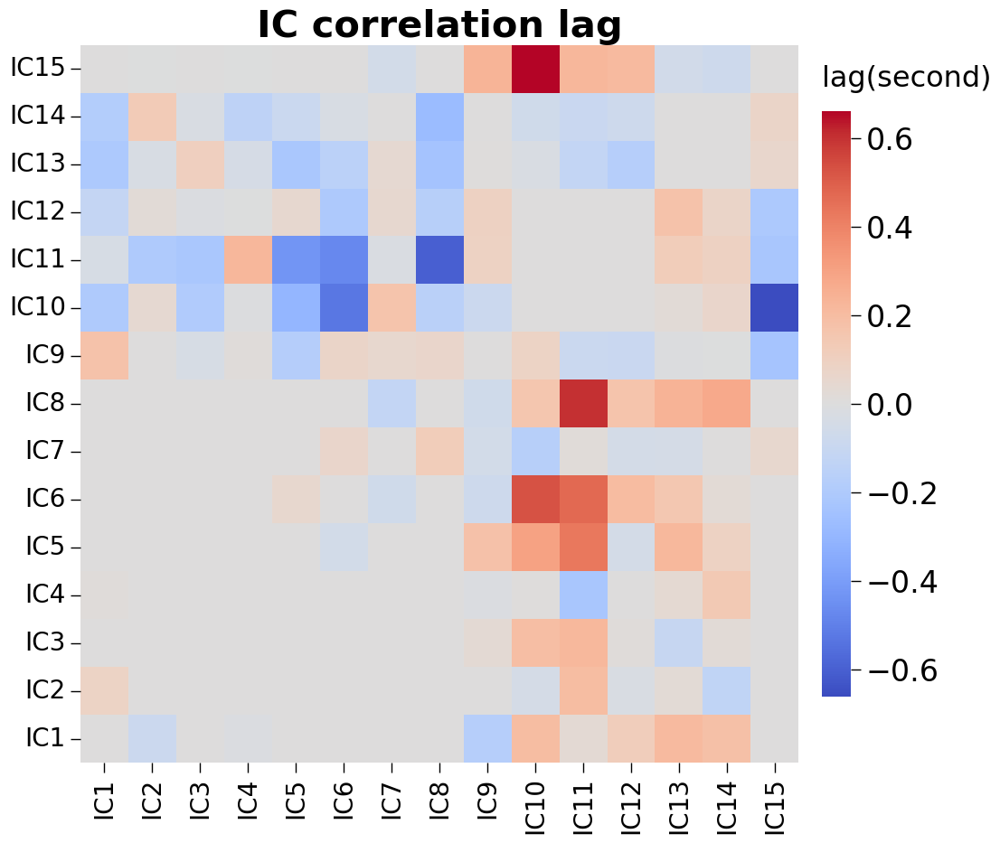

In [29]:
plot_heatmap(IC_lag.mean(0)/10, xlabel=IC_list,  ylabel=IC_list, cmap='coolwarm', center=0, title='IC correlation lag', colorbar_name='lag(second)',
             outfile=pjoin(path_out_gICA, 'timecourse','IC correlation lag.png'), dpi=300, annot=False)

## correlation with feature

In [65]:

with np.load("../video_features_adjust.npz") as data:
    brightness, contrast, motion_energy, frame_diff, fps = \
        data['brightness'], data['contrast'], data['motion_energy'], data['frame_diff'], data['fps']


In [66]:

brightness.shape


(14, 150)

In [67]:
select_Timecourse.shape

(15, 200, 14, 5, 36)

In [69]:
#%%
from scipy.signal import correlate
from scipy.stats import zscore
# 标准化钙信号和刺激参数

timecourse_z = zscore(select_Timecourse[:,pre_length:pre_length+n_frame].mean((-1,-2)).transpose(0,2,1).reshape(select_nIC, n_movie*n_frame), axis=1)
brightness_z = zscore(brightness).reshape(-1)
contrast_z = zscore(contrast).reshape(-1)
motion_energy_z = zscore(motion_energy).reshape(-1)
frame_diff_z = zscore(frame_diff).reshape(-1)


In [70]:
#%%
def lagged_corr(x, y, max_lag):
    """计算时滞互相关（标准化Pearson）"""
    corr = correlate(x, y, mode='full', method='auto') / (len(x) * np.std(x) * np.std(y))
    mid = len(corr) // 2
    return corr[mid - max_lag : mid + max_lag + 1]

max_lag = 20  # 最大滞后帧数
lags = np.arange(-max_lag, max_lag + 1)

def lagged_corr_feature(timecourse_z, feature_z):
    n_IC = timecourse_z.shape[0]
    corr_values = np.zeros((n_IC,max_lag*2+1))
    for i_area in range(n_IC):
        corr_values[i_area] = lagged_corr(timecourse_z[i_area, :], feature_z, max_lag)
    return corr_values

corr_values_brightness = lagged_corr_feature(timecourse_z, brightness_z)
corr_values_contrast = lagged_corr_feature(timecourse_z, contrast_z)
corr_values_motion_energy = lagged_corr_feature(timecourse_z, motion_energy_z)
corr_values_frame_diff = lagged_corr_feature(timecourse_z, frame_diff_z)


In [86]:
def plot_heatmap_4in1(data_list, data_titles, lags, area_list, xtitle='lags', ytitle='brain areas',
                      cmap='coolwarm', center=0, outfile=None, dpi=300):
    import seaborn as sns
    import matplotlib.pyplot as plt
    import numpy as np

    all_data = np.concatenate([d.ravel() for d in data_list])
    vmax = np.nanmax(all_data)
    vmin = np.nanmin(all_data)
    # -------- figure --------
    fig, axes = plt.subplots(1, 4, figsize=(4 * len(lags)//2, len(area_list)), sharey=True)
    fig.subplots_adjust(wspace=0.2)
    fig.set_facecolor('white')

    # x 轴刻度：lags / 10，保留 1 位小数
    xlabels = [f'{x / 10:.1f}' if i % 5 == 0 else ''
        for i, x in enumerate(lags)]

    mappable = None

    for ax, data, title in zip(axes, data_list, data_titles):
        hm = sns.heatmap(
            data, ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, center=center,
            square=False, linewidths=0, cbar=False,
            xticklabels=xlabels, yticklabels=area_list
        )

        ax.set_title(title, fontsize=60, pad=40)
        ax.tick_params(axis='x', labelsize=40)
        ax.tick_params(axis='y', labelsize=40, labelrotation=0)
        ax.invert_yaxis()

        if mappable is None:
            mappable = hm.collections[0]

    axes[0].set_ylabel(ytitle, fontsize=50, labelpad=20)
    fig.supxlabel('time lag (second)', fontsize=50, y=0.01)

    # -------- 统一 colorbar --------
    cbar = fig.colorbar(mappable, ax=axes, pad=0.02, shrink=0.8
                        # , fraction=0.03, aspect=30
                        )
    cbar.ax.tick_params(labelsize=35)
    cbar.set_label('Pearson R', fontsize=50, labelpad=15)

    if outfile:
        plt.savefig(outfile, dpi=dpi, bbox_inches='tight')

    plt.show()



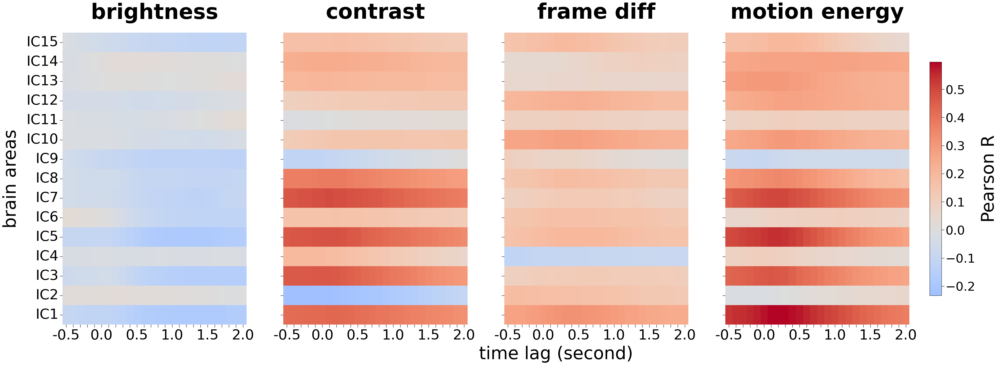

In [87]:

#%%
plot_heatmap_4in1(
    data_list=[
        corr_values_brightness[:,15:],
        corr_values_contrast[:,15:],
        corr_values_frame_diff[:,15:],
        corr_values_motion_energy[:,15:]
    ],
    data_titles=['brightness', 'contrast', 'frame diff', 'motion energy'],
    lags=lags[15:], area_list=IC_list, center=0, dpi=200,
    outfile=pjoin(path_out_gICA, 'corr_all_4in1.png')
)



In [88]:

#%%
def plot_lag_corr_4in1(lags, corr_values_list, area_list, titles, outfile=None):

    import matplotlib.pyplot as plt
    from matplotlib.ticker import FormatStrFormatter

    fig, axes = plt.subplots(1, 4, figsize=(16, 6), sharey=False)
    fig.subplots_adjust(wspace=0.3)
    fig.set_facecolor('white')

    for ax, corr_values, title in zip(axes, corr_values_list, titles):
        for i_area in range(len(area_list)):
            ax.plot(lags, corr_values[i_area], label=area_list[i_area])

        ax.set_title(title, fontsize=20, pad=10)
        ax.set_xlim(min_lag, max_lag)
        ax.grid(True)
        ax.tick_params(axis='both', labelsize=14)
        ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
        # 每隔 5 个 lag 一个刻度
        tick_idx = np.arange(0, len(lags), 5)
        tick_lags = np.array(lags)[tick_idx]
        ax.set_xticks(tick_lags)
        ax.set_xticklabels([f"{x * 0.1:.1f}" for x in tick_lags])
    axes[0].set_ylabel('Pearson R', fontsize=16)

    # 统一 X 轴标签
    fig.supxlabel('time lag (second)', fontsize=18, y=0.008)

    # 只放一个 legend（放在最右侧子图外）
    axes[-1].legend(
        loc='upper left',
        bbox_to_anchor=(1.05, 1),
        fontsize=16,
        frameon=False
    )

    if outfile:
        plt.savefig(outfile, bbox_inches='tight', dpi=300)

    plt.show()



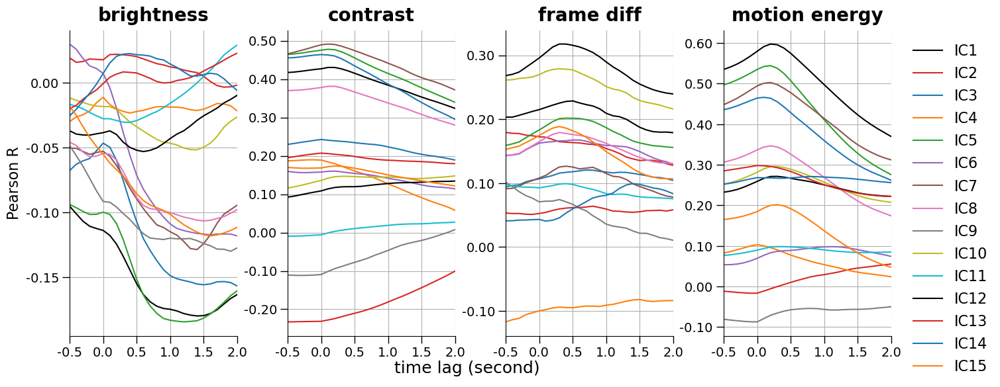

In [90]:

#%%
min_lag, max_lag = lags[15], lags[-1]

plot_lag_corr_4in1(
    lags=lags[15:],
    corr_values_list=[
        corr_values_brightness[:,15:],
        corr_values_contrast[:,15:],
        corr_values_frame_diff[:,15:],
        corr_values_motion_energy[:,15:]
    ],
    area_list=IC_list,
    titles=[
        'brightness',
        'contrast',
        'frame diff',
        'motion energy'
    ],
    outfile='Cross-Correlation_4in1.png'
)



In [ ]:
with np.load("../video_features.npz") as data:
    brightness1, _, _, _, _ = \
        data['brightness'], data['contrast'], data['motion_energy'], data['frame_diff'], data['fps']


In [ ]:
brightness1_z = zscore(brightness1).reshape(-1)
timecourse1_z = zscore(select_Timecourse[:,pre_length:pre_length+n_frame,:,:,:17].mean((-1,-2)).transpose(0,2,1).reshape(n_IC, n_movie*n_frame), axis=1)
timecourse2_z = zscore(select_Timecourse[:,pre_length:pre_length+n_frame,:,:,17:].mean((-1,-2)).transpose(0,2,1).reshape(n_IC, n_movie*n_frame), axis=1)


In [ ]:
corr_values_brightness1 = lagged_corr_feature(timecourse1_z, brightness1_z)
corr_values_brightness2 = lagged_corr_feature(timecourse2_z, brightness_z)



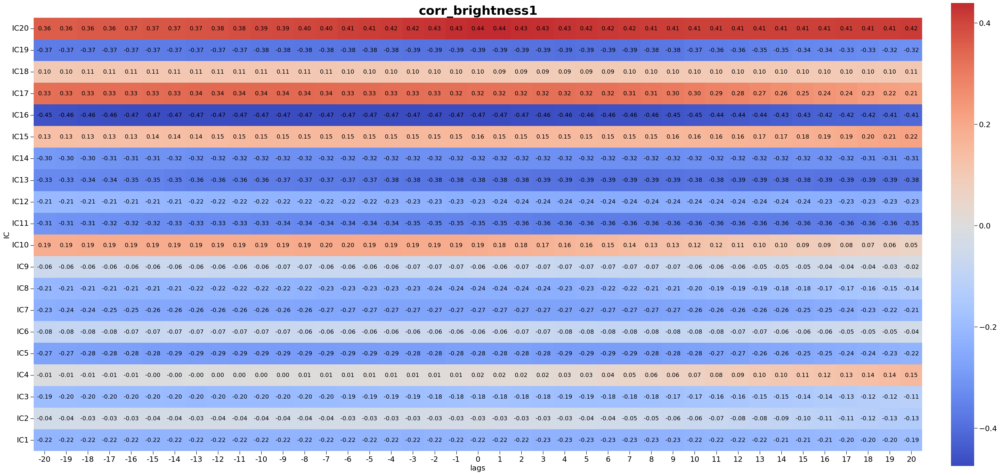

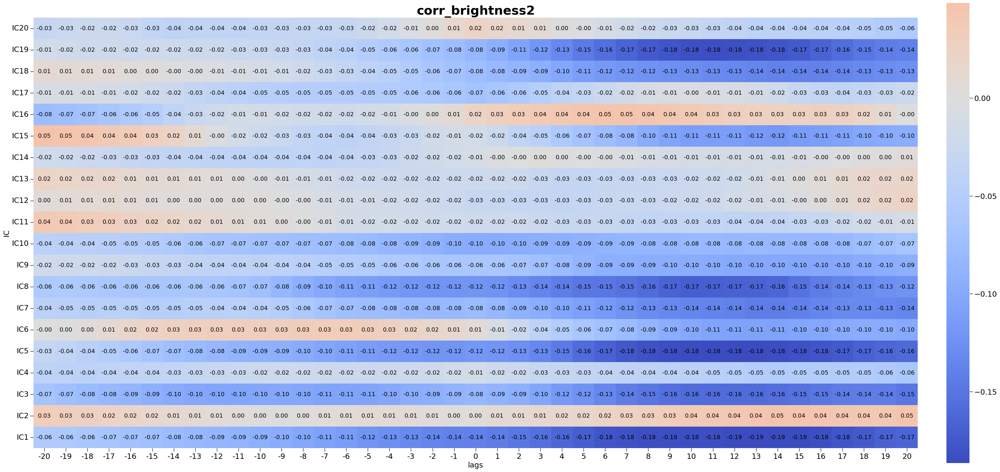

In [308]:
plot_heatmap(corr_values_brightness1, xlabel=lags, ylabel=IC_list, xtitle='lags', ytitle='IC', cmap='coolwarm',
             center = 0, title='corr_brightness1', outfile=pjoin(path_out_gICA, 'timecourse', 'corr_brightness1.png'), dpi=200, annot=True)
plot_heatmap(corr_values_brightness2, xlabel=lags, ylabel=IC_list, xtitle='lags', ytitle='IC', cmap='coolwarm',
             center = 0, title='corr_brightness2', outfile=pjoin(path_out_gICA, 'timecourse', 'corr_brightness2.png'), dpi=200, annot=True)

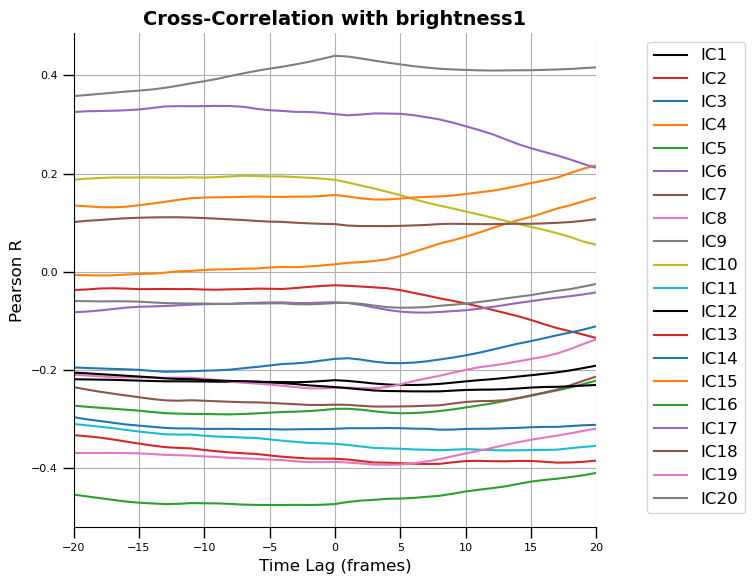

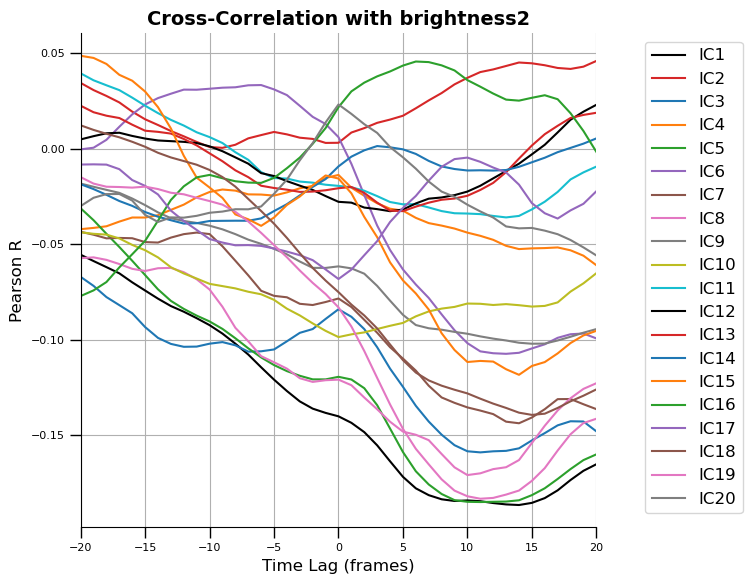

In [309]:
plot_lag_corr(lags, corr_values_brightness1, area_list=IC_list, title='Cross-Correlation with brightness1', outfile=pjoin(path_out_gICA, 'timecourse','Cross-Correlation with brightness1.png'))
plot_lag_corr(lags, corr_values_brightness2, area_list=IC_list, title='Cross-Correlation with brightness2', outfile=pjoin(path_out_gICA, 'timecourse','Cross-Correlation with brightness2.png'))
